# SoundSense екі терең оқыту моделін толық салыстыру

**YAMNet transfer және EfficientNet-B0 transfer · ESC-10 · бірдей ресми folds · seed 42**

Бұл ноутбук деректерді тексеруден бастап frozen белгілерді шығару, екі жаңа head-ты оқыту,
fixed test және бес fold OOF бағалауы, архитектура сызбалары, барлық графиктер мен нәтижелерді
жүктеуге дейінгі толық жұмысты қамтиды. Екі модель де терең CNN қолданады.

**Дайын нұсқа оқытылған:** ноутбуктің сақталған ұяшық нәтижелері осы компьютерде шын орындалған
оқыту мен есептеуден алынған. Олар Google серверінде орындалды деген мәлімдеме емес.
Тіркелген дайын пакетте 10 оқытылған head, екі frozen backbone, 400 түпнұсқа аудио,
белгі кэштері, нақты epoch журналдары, болжамдар және экспортталған графиктер бар.

**58 сурет:** 53 ғылыми график және 5 архитектура/әдіснама сызбасы. Әр сурет PNG 300 dpi,
SVG және PDF түрінде сақталады. Сандық негіздері CSV/JSON, epoch history және бастапқы WAV/NPZ файлдарында берілген.
Ноутбуктағы суреттер — ықшам алдын ала көрініс; архивте толық 300 dpi түпнұсқалар бар.

### Colab-та төрт қадам
1. Осы `.ipynb` файлын [Google Colab](https://colab.research.google.com/) → File → Upload notebook арқылы ашыңыз.
2. Runtime → Change runtime type → **T4 GPU**, Runtime Version → **2026.04** таңдаңыз. Бұл Python 3.12 ортасын береді.
3. Runtime → Run all басыңыз. Сұралғанда `SoundSense_2Models_Trained_Colab.zip` пакетін жүктеңіз.
4. Қайта оқыту үшін төмендегі `RUN_MODE = "retrain"`; дайын салмақтарды тексеріп графиктерді жасау үшін `"use_trained"` таңдаңыз.

Архивсіз де іске қосуға болады: `USE_BUNDLE=False` қойыңыз. Сол кезде ресми ESC-10 аудиосы
және pretrained backbone-дар жүктеліп, белгілер қайта есептеледі. Бұл интернет пен қосымша уақытты қажет етеді.


## 1 Іске қосу параметрлері

`retrain` — frozen backbone-дан алынған белгілерге екі модельдің ESC-10 head-тарын нақты оқытады.
`use_trained` — пакеттегі дайын checkpoint пен train статистикасын тексереді, қайта оқытпайды.
`RECOMPUTE_FEATURES=True` барлық аудиодан белгілерді қайта шығарады; бұл жағдайда жаңа head оқыту керек.


In [1]:
import os,sys,json,hashlib,subprocess,importlib.util,importlib.metadata,zipfile
from pathlib import Path
IN_COLAB=bool(os.environ.get('COLAB_RELEASE_TAG')) or (importlib.util.find_spec('google') is not None and importlib.util.find_spec('google.colab') is not None)
RUN_MODE = 'retrain' # @param ['retrain', 'use_trained']
USE_BUNDLE = True # @param {type:'boolean'}
RECOMPUTE_FEATURES = False # @param {type:'boolean'}
BUNDLE_PATH = '' # @param {type:'string'}
DOWNLOAD_RESULTS = True # @param {type:'boolean'}
ROOT_PATH=Path(os.environ.get('SOUNDSENSE_NOTEBOOK_ROOT','/content/SoundSense_2Models' if IN_COLAB else './SoundSense_2Models')).resolve()
ROOT_PATH.mkdir(parents=True,exist_ok=True)
if RECOMPUTE_FEATURES and RUN_MODE=='use_trained':
    raise ValueError('RECOMPUTE_FEATURES үшін RUN_MODE=retrain таңдаңыз.')
print('Mode:',RUN_MODE,'| Google Colab:',IN_COLAB)


Mode: retrain | Google Colab: False


## 2 Дайын пакетті ашу

Бұл қадам өзіңіз жүктеген ZIP ішіндегі аудио, backbone, кэш және оқытылған нәтижелерді ашады.
Файл жолдары тек жұмыс қалтасының ішіне жазылатындай тексеріледі. Деректердің SHA-256 мәндері
келесі кезеңдерде қайта тексеріледі. Дайын пакет болса, сыртқы деректерді қайта жүктеудің қажеті жоқ.


In [2]:
if USE_BUNDLE and not (ROOT_PATH/'assets/metadata/manifest.csv').exists():
    if not BUNDLE_PATH:
        if not IN_COLAB:
            raise FileNotFoundError('BUNDLE_PATH ішіне дайын ZIP жолын көрсетіңіз.')
        from google.colab import files
        print('SoundSense_2Models_Trained_Colab.zip файлын таңдаңыз')
        uploaded=files.upload()
        candidates=[Path(n) for n in uploaded if n.lower().endswith('.zip')]
        if len(candidates)!=1: raise ValueError('Бір дайын ZIP файлын таңдаңыз.')
        BUNDLE_PATH=str(candidates[0])
    with zipfile.ZipFile(BUNDLE_PATH) as archive:
        for info in archive.infolist():
            target=(ROOT_PATH/info.filename).resolve()
            if not target.is_relative_to(ROOT_PATH) or info.filename.startswith(('/', '\\')):
                raise ValueError('ZIP ішіндегі жарамсыз жол')
        archive.extractall(ROOT_PATH)
    print('Prepared package extracted.')
else:
    print('Prepared assets already found.' if (ROOT_PATH/'assets').exists() else 'Official files will be downloaded.')
package_manifest=ROOT_PATH/'package_manifest.json'
if package_manifest.exists():
    records=json.loads(package_manifest.read_text(encoding='utf-8'))
    for name,digest in records['immutable_assets_sha256'].items():
        path=ROOT_PATH/name
        if not path.is_file() or hashlib.sha256(path.read_bytes()).hexdigest()!=digest:
            raise ValueError('Package asset checksum mismatch: '+name)
    print('Verified package assets:',len(records['immutable_assets_sha256']))


Prepared assets already found.


## 3 Кітапханалар және бөлек TensorFlow ортасы

Негізгі ортада PyTorch head-тары мен EfficientNet жұмыс істейді. YAMNet жеке Python процесінде
CPU арқылы белгілер шығарады. TensorFlow үшін бөлек орта жасалуы Colab-тың JAX/Keras және
GPU жад баптауларымен араласуды азайтады. Дайын кэш қолданылса да, соңында нақты аудиомен
екі жүйенің толық inference жолы тексеріледі.

Ұсынылатын орта — Colab **2026.04 / Python 3.12**. Нұсқаны таңдау жолы
[Colab ресми нұсқаулығында](https://research.google.com/colaboratory/runtime-version-faq.html) көрсетілген.


In [3]:
if IN_COLAB:
    if not (3,10)<=sys.version_info[:2]<=(3,12):
        raise RuntimeError('Runtime → Change runtime type → Runtime Version 2026.04 таңдаңыз: Python 3.12 қажет.')
    def installed(name):
        try: return importlib.metadata.version(name).split('+')[0]
        except importlib.metadata.PackageNotFoundError: return ''
    if installed('torch')!='2.10.0' or installed('torchvision')!='0.25.0':
        subprocess.run([sys.executable,'-m','pip','install','-q','torch==2.10.0','torchvision==0.25.0',
                        '--index-url','https://download.pytorch.org/whl/cu126'],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','numpy>=1.26,<2.3','pandas==2.3.3',
                    'librosa==0.11.0','soundfile==0.13.1','scipy==1.16.3','scikit-learn==1.7.2',
                    'matplotlib==3.10.7','soxr==1.1.0','pillow>=10','packaging','virtualenv'],check=True)
    tf_environment=ROOT_PATH/'.tf_env'
    TF_PYTHON=tf_environment/'bin/python'
    if not TF_PYTHON.is_file():
        subprocess.run([sys.executable,'-m','virtualenv',str(tf_environment)],check=True)
        subprocess.run([str(TF_PYTHON),'-m','pip','install','-q','tensorflow==2.20.0','tf-keras==2.20.1',
                        'tensorflow-hub==0.16.1','numpy==2.2.6','protobuf==5.29.5','keras==3.11.3'],check=True)
else:
    TF_PYTHON=Path(os.environ['SOUNDSENSE_NOTEBOOK_TF_PYTHON'])
    print('Local validation uses the already installed isolated TensorFlow interpreter.')
assert TF_PYTHON.is_file()
print('PyTorch main environment and isolated TensorFlow environment ready.')


Local validation uses the already installed isolated TensorFlow interpreter.
PyTorch main environment and isolated TensorFlow environment ready.


## 4 Негізгі функциялар және нақты орындалу ортасы

Төмендегі функциялар файлдарды SHA-256 арқылы тексереді, seed орнатады және суреттерді
үш форматта экспорттайды. Нәтижелер `run` қалтасында жиналады.


In [4]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import sys, json, hashlib, time, random, shutil, subprocess, platform, inspect, io
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from urllib.request import Request, urlopen
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from scipy.ndimage import zoom
from scipy.stats import binomtest
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve,
    average_precision_score)
from PIL import Image

NAMES = ['yamnet_transfer','efficientnet_b0_mel']
TITLES = {'yamnet_transfer':'YAMNet transfer','efficientnet_b0_mel':'EfficientNet-B0 transfer'}
LABELS = ['dog','rooster','rain','sea_waves','crackling_fire','crying_baby','sneezing','clock_tick','helicopter','chainsaw']
KAZAKH = ['Иттің үруі','Әтеш','Жаңбыр','Теңіз толқындары','Оттың шытырлауы','Сәбидің жылауы','Түшкіру','Сағат тықылы','Тікұшақ','Моторлы ара']
COMMIT = '33c8ce9eb2cf0b1c2f8bcf322eb349b6be34dbb6'
YAMNET_URL = 'https://tfhub.dev/google/yamnet/1'
RECIPES = {
    'yamnet_transfer':dict(dimension=1024,epochs=160,patience=25,batch_size=16,lr=.001,weight_decay=.001),
    'efficientnet_b0_mel':dict(dimension=1280,epochs=120,patience=20,batch_size=16,lr=.002,weight_decay=.001)}
MEL_CFG = dict(sample_rate=16000,duration=5,n_fft=1024,hop=512,n_mels=64,fmin=0,fmax=8000,top_db=80,frames=128)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,
                     'axes.spines.right':False,'savefig.dpi':300})
COLORS = {'yamnet_transfer':'#2166ac','efficientnet_b0_mel':'#c75b12'}


def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):
            h.update(chunk)
    return h.hexdigest()


def identity(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,separators=(',',':')).encode()).hexdigest()


def dump(path,value):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(value,ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf-8')


def read(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


def seed_all(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
    torch.use_deterministic_algorithms(True)


def configure(root):
    global ROOT,ASSETS,OUT,DEVICE,FIGURES
    ROOT=Path(root).resolve(); ASSETS=ROOT/'assets'; OUT=ROOT/'run'
    for folder in ['models','history','predictions','metrics','figures/png','figures/svg','figures/pdf','architecture','tables']:
        (OUT/folder).mkdir(parents=True,exist_ok=True)
    DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    torch.set_num_threads(4); seed_all()
    FIGURES=[]
    print('Device:',DEVICE,torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU')
    dump(OUT/'environment.json',dict(python=sys.version,platform=platform.platform(),
        torch=str(torch.__version__),numpy=np.__version__,pandas=pd.__version__,
        librosa=librosa.__version__,device=str(DEVICE),seed=42,
        executed_in_colab=bool(os.environ.get('COLAB_RELEASE_TAG')),
        execution_note='Runtime outputs belong to the environment recorded here; training metadata remains with each checkpoint.'))


def show_png(path):
    if '_NOTEBOOK_CAPTURE' in globals():
        _NOTEBOOK_CAPTURE(Path(path))
    else:
        try:
            from IPython.display import display, Image as DisplayImage
            with Image.open(path) as im:
                preview=im.convert('RGB')
                preview.thumbnail((1600,2400),Image.Resampling.LANCZOS)
                buffer=io.BytesIO(); preview.save(buffer,format='PNG')
            display(DisplayImage(data=buffer.getvalue()))
        except ImportError:
            print('Figure:',Path(path).name)


def save(fig,name,caption,kind='result'):
    fig.tight_layout()
    for fmt in ['png','svg','pdf']:
        fig.savefig(OUT/f'figures/{fmt}/{name}.{fmt}',bbox_inches='tight',dpi=300)
    plt.close(fig)
    entry=dict(name=name,caption=caption,kind=kind,png=f'figures/png/{name}.png')
    FIGURES.append(entry)
    show_png(OUT/entry['png'])


def fetch(url,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    for attempt in range(4):
        try:
            with urlopen(Request(url,headers={'User-Agent':'SoundSense-coursework/2.0'}),timeout=60) as response:
                temp=path.with_suffix(path.suffix+'.part')
                with temp.open('wb') as out: shutil.copyfileobj(response,out)
            temp.replace(path)
            return
        except (OSError,ValueError):
            if attempt==3: raise
            time.sleep(2**attempt)


def safe_load(path):
    from packaging.version import Version
    if Version(torch.__version__.split('+')[0]) < Version('2.10.0'):
        raise RuntimeError('Use torch >= 2.10.0 before loading trusted weights-only checkpoints.')
    return torch.load(path,map_location='cpu',weights_only=True)

configure(ROOT_PATH)


Device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


## 5 Екі модельдің терең оқыту архитектурасы

**YAMNet** — AudioSet-те үйренген MobileNetV1 терең CNN. Ол 96×64 log Mel патчтан 1024
embedding шығарады. Уақыт бойынша орташа embedding train mean/std арқылы стандартталады.
**EfficientNet-B0** — ImageNet-те үйренген MBConv және Squeeze-and-Excitation блоктары бар терең CNN.
Бұл жұмыста Mel кескіні үш арнаға көшіріліп, 224×224 пішініне bilinear түрлендірумен беріледі;
жаһандық pooling 1280 embedding береді. Бұл жобалық Mel түрлендіруі Torchvision-ның әдеттегі
фотосурет resize/crop рецептімен бірдей емес.

Екі жүйеде де backbone **frozen**, тек `Dropout(0.2) → Linear(d,10)` head оқиды.
Trainable head саны: YAMNet **10 250**, EfficientNet **12 810** параметр. Бұлар бүкіл терең
желінің параметр саны емес. Бұл әдіс — терең белгілерге негізделген transfer learning;
backbone-ды бастапқыдан оқыту немесе fine-tuning жүргізілмейді.

Depthwise операциясы әр арнадағы жергілікті өрнекті, pointwise арналар аралығын өңдейді.
MBConv expansion, depthwise, SE және projection қолданады; residual тек stride=1 және арна
өлшемдері тең кезде қосылады. MBConv1-де expansion ratio=1 болғандықтан expansion қабаты жоқ.

Дереккөздер: [YAMNet](https://www.tensorflow.org/tutorials/audio/transfer_learning_audio),
[MobileNet](https://arxiv.org/abs/1704.04861), [EfficientNet](https://arxiv.org/abs/1905.11946),
[Torchvision B0](https://docs.pytorch.org/vision/0.25/models/generated/torchvision.models.efficientnet_b0.html).


YAMNet transfer
    stage  first_block_stride  output_channels  repeats
  Conv3x3                   2               32        1
DSConv3x3                   1               64        1
DSConv3x3                   2              128        1
DSConv3x3                   1              128        1
DSConv3x3                   2              256        1
DSConv3x3                   1              256        1
DSConv3x3                   2              512        1
DSConv3x3                   1              512        5
DSConv3x3                   2             1024        1
DSConv3x3                   1             1024        1
EfficientNet-B0 transfer
     stage  first_block_stride  output_channels  repeats
   Stem3x3                   2               32        1
MBConv1 k3                   1               16        1
MBConv6 k3                   2               24        2
MBConv6 k5                   2               40        2
MBConv6 k3                   2               80        3
M

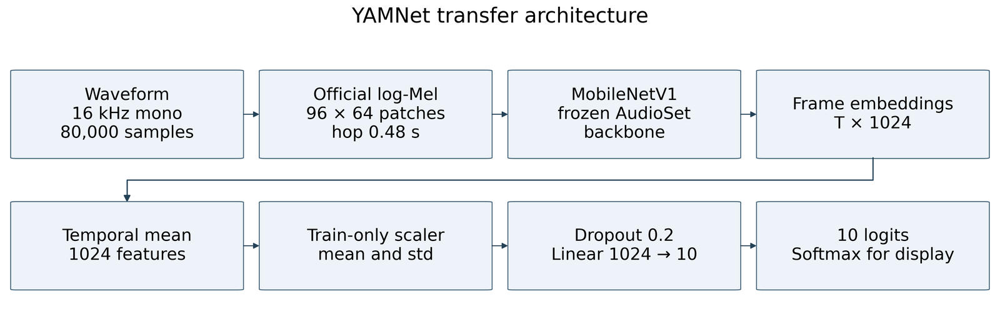

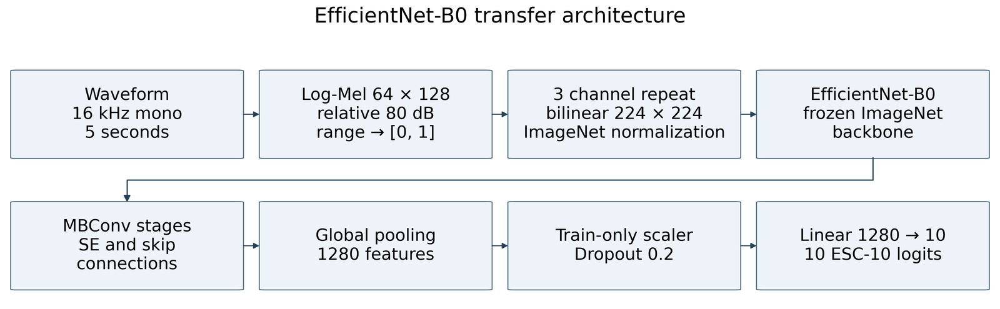

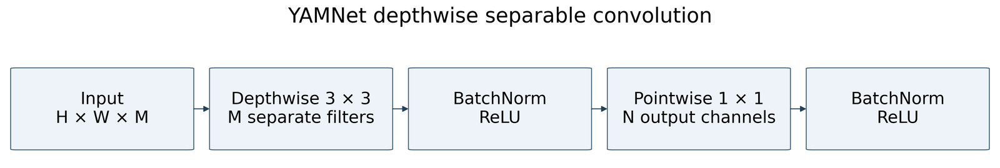

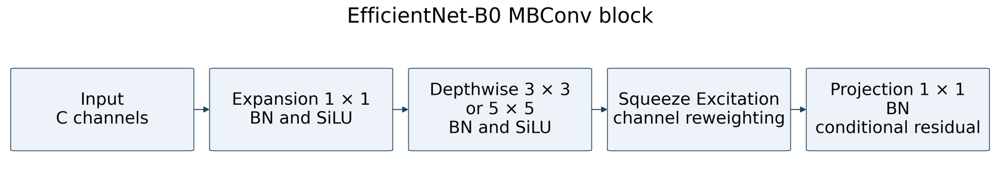

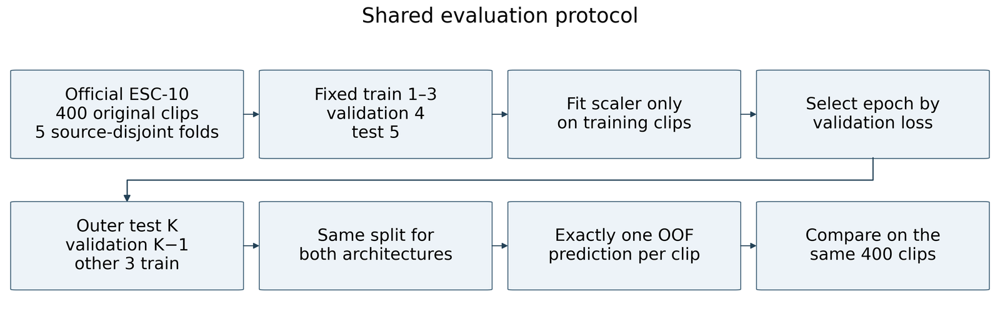

In [18]:
def diagram(name,title,rows,caption):
    from matplotlib.path import Path as DrawingPath
    fig,ax=plt.subplots(figsize=(15,max(2.6,len(rows)*2.35)))
    ax.set(xlim=(0,1),ylim=(0,len(rows))); ax.axis('off'); ax.set_title(title,pad=18,fontsize=22)
    for row,labels in enumerate(rows):
        count=len(labels); gap=.028; width=(.98-gap*(count-1))/count; y=len(rows)-row-.9
        for i,label in enumerate(labels):
            x=.01+i*(width+gap)
            ax.add_patch(FancyBboxPatch((x,y),width,.66,boxstyle='round,pad=0.006',facecolor='#edf3f8',edgecolor='#44647a'))
            ax.text(x+width/2,y+.33,label,ha='center',va='center',fontsize=18)
            if i<count-1:
                ax.add_patch(FancyArrowPatch((x+width+.004,y+.33),(x+width+gap-.004,y+.33),arrowstyle='-|>',mutation_scale=13,color='#244257'))
        if row+1<len(rows):
            next_count=len(rows[row+1]); next_width=(.98-gap*(next_count-1))/next_count
            last_x=.01+(count-1)*(width+gap)+width/2; first_x=.01+next_width/2
            route=DrawingPath([(last_x,y),(last_x,y-.17),(first_x,y-.17),(first_x,y-.34)],
                              [DrawingPath.MOVETO,DrawingPath.LINETO,DrawingPath.LINETO,DrawingPath.LINETO])
            ax.add_patch(FancyArrowPatch(path=route,arrowstyle='-|>',mutation_scale=15,color='#244257',lw=1.3))
    save(fig,name,caption,'architecture')


def architecture_figures():
    diagram('architecture_yamnet','YAMNet transfer architecture',[
        ['Waveform\n16 kHz mono\n80,000 samples','Official log-Mel\n96 × 64 patches\nhop 0.48 s','MobileNetV1\nfrozen AudioSet\nbackbone','Frame embeddings\nT × 1024'],
        ['Temporal mean\n1024 features','Train-only scaler\nmean and std','Dropout 0.2\nLinear 1024 → 10','10 logits\nSoftmax for display']],
        'YAMNet frozen MobileNetV1 backbone және ESC-10 үшін жаңа head')
    diagram('architecture_efficientnet','EfficientNet-B0 transfer architecture',[
        ['Waveform\n16 kHz mono\n5 seconds','Log-Mel 64 × 128\nrelative 80 dB\nrange → [0, 1]','3 channel repeat\nbilinear 224 × 224\nImageNet normalization','EfficientNet-B0\nfrozen ImageNet\nbackbone'],
        ['MBConv stages\nSE and skip\nconnections','Global pooling\n1280 features','Train-only scaler\nDropout 0.2','Linear 1280 → 10\n10 ESC-10 logits']],
        'EfficientNet-B0 үшін жобада қолданылатын Mel preprocessing және frozen backbone')
    diagram('architecture_yamnet_block','YAMNet depthwise separable convolution',[[
        'Input\nH × W × M','Depthwise 3 × 3\nM separate filters','BatchNorm\nReLU','Pointwise 1 × 1\nN output channels','BatchNorm\nReLU']],
        'Depthwise уақыт-жиілік өрнектерін өңдейді pointwise арналарды біріктіреді')
    diagram('architecture_mbconv','EfficientNet-B0 MBConv block',[[
        'Input\nC channels','Expansion 1 × 1\nBN and SiLU','Depthwise 3 × 3\nor 5 × 5\nBN and SiLU','Squeeze Excitation\nchannel reweighting','Projection 1 × 1\nBN\nconditional residual']],
        'MBConv expansion ratio бірден үлкен болса expansion қолданылады residual тек stride 1 және кіріс шығыс арналары тең болғанда қосылады')
    diagram('architecture_protocol','Shared evaluation protocol',[
        ['Official ESC-10\n400 original clips\n5 source-disjoint folds','Fixed train 1–3\nvalidation 4\ntest 5','Fit scaler only\non training clips','Select epoch by\nvalidation loss'],
        ['Outer test K\nvalidation K−1\nother 3 train','Same split for\nboth architectures','Exactly one OOF\nprediction per clip','Compare on the\nsame 400 clips']],
        'Екі модель үшін бірдей ресми folds және train-only статистика')
    yam=[['Conv3x3',2,32,1],['DSConv3x3',1,64,1],['DSConv3x3',2,128,1],['DSConv3x3',1,128,1],
         ['DSConv3x3',2,256,1],['DSConv3x3',1,256,1],['DSConv3x3',2,512,1],['DSConv3x3',1,512,5],
         ['DSConv3x3',2,1024,1],['DSConv3x3',1,1024,1]]
    eff=[['Stem3x3',2,32,1],['MBConv1 k3',1,16,1],['MBConv6 k3',2,24,2],['MBConv6 k5',2,40,2],
         ['MBConv6 k3',2,80,3],['MBConv6 k5',1,112,3],['MBConv6 k5',2,192,4],['MBConv6 k3',1,320,1],['Conv1x1',1,1280,1]]
    for name,rows in [('yamnet_transfer',yam),('efficientnet_b0_mel',eff)]:
        table=pd.DataFrame(rows,columns=['stage','first_block_stride','output_channels','repeats'])
        table.to_csv(OUT/f'architecture/{name}_stages.csv',index=False)
        print(TITLES[name]); print(table.to_string(index=False))
    print('Trainable head parameters: YAMNet 10,250; EfficientNet-B0 12,810. These are not full backbone counts.')

architecture_figures()


## 6 ESC-10 деректерін алу және leakage тексеруі

400 бес секундтық түпнұсқа, он санат, әр санатта 40 мысал. Ресми fold-та әр санаттың сегіз
клипі болады. Fixed train folds 1–3, validation fold 4, test fold 5. `src_file` бастапқы жазбасы
бөліктер арасында қайталанбауы тексеріледі. Дерек көзі pinned commit-пен бекітілген.
ESC-10 CC BY 3.0 атрибуциясы мен upstream лицензиясы пакетте сақталады.


ESC-10: 400 clips; fixed split: 240 train / 80 validation / 80 test


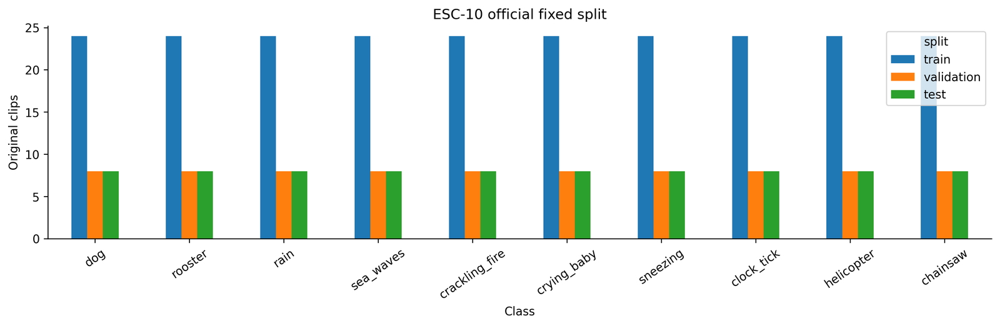

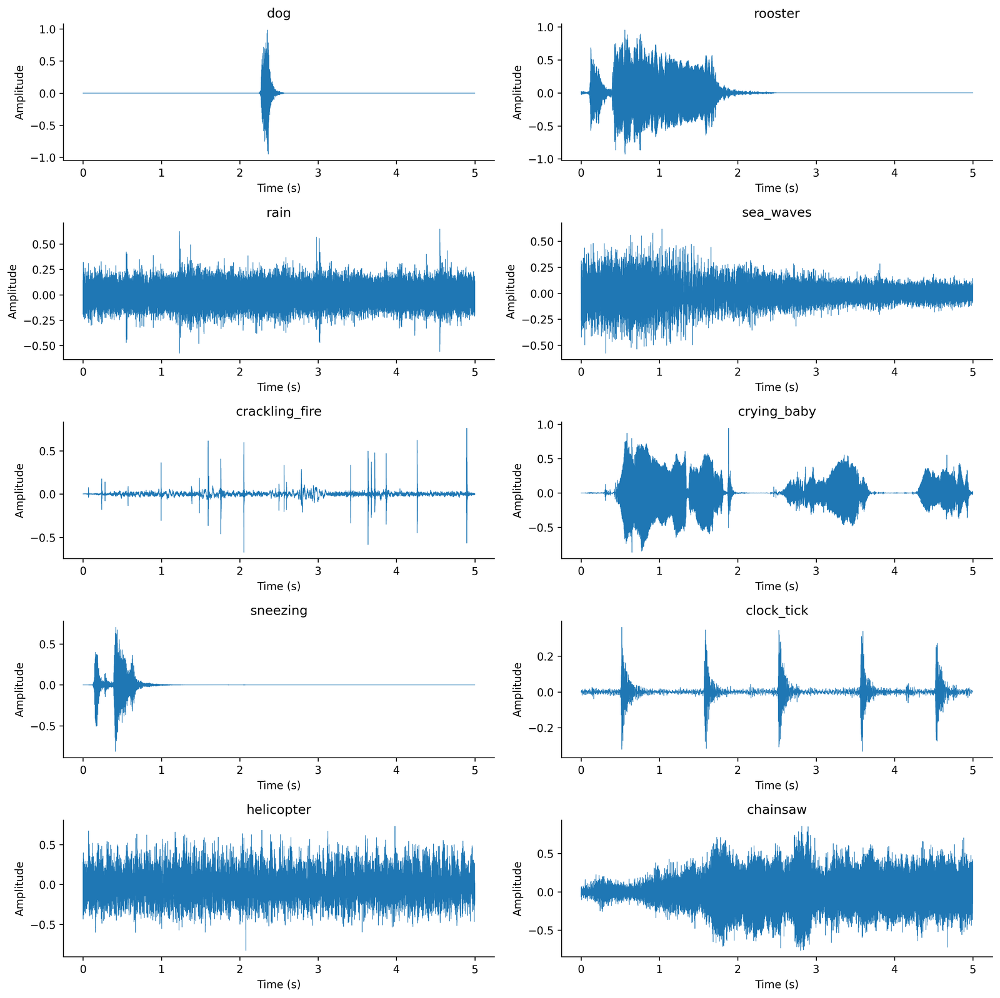

In [6]:
def prepare_dataset():
    meta=ASSETS/'metadata'; raw=ASSETS/'audio'
    meta.mkdir(parents=True,exist_ok=True); raw.mkdir(parents=True,exist_ok=True)
    if (meta/'manifest.csv').exists():
        df=pd.read_csv(meta/'manifest.csv',dtype={'src_file':str})
    else:
        base=f'https://raw.githubusercontent.com/karolpiczak/ESC-50/{COMMIT}'
        for remote,local in [('meta/esc50.csv','esc50.csv'),('LICENSE','LICENSE'),('README.md','UPSTREAM_README.md')]:
            fetch(f'{base}/{remote}',meta/local)
        data=pd.read_csv(meta/'esc50.csv',dtype={'src_file':str})
        df=data[data.esc10.astype(str).str.lower().eq('true')].sort_values('filename').reset_index(drop=True).copy()
        df['class_index']=df.category.map({name:i for i,name in enumerate(LABELS)})
        df['split']=df.fold.map({1:'train',2:'train',3:'train',4:'validation',5:'test'})
        df['source_url']=[f'{base}/audio/{name}' for name in df.filename]
    assert len(df)==400 and df.filename.is_unique
    assert set(df.category)==set(LABELS) and set(df.fold)==set(range(1,6))
    assert (df.groupby(['fold','category']).size()==8).all()
    assert (df.groupby('src_file').fold.nunique()==1).all(), 'Source recording leakage'
    assert np.array_equal(df.category.map(dict(zip(LABELS,range(10)))),df.class_index)
    def obtain(row):
        path=raw/row.filename
        if path.exists() and ('sha256' not in df or sha(path)==row.sha256): return
        fetch(row.source_url,path)
        if 'sha256' in df and sha(path)!=row.sha256: raise ValueError(f'Audio checksum: {row.filename}')
    with ThreadPoolExecutor(max_workers=6) as pool:
        list(pool.map(obtain,df.itertuples()))
    if 'sha256' not in df:
        df['sha256']=[sha(raw/name) for name in df.filename]
    df.to_csv(meta/'manifest.csv',index=False)
    dump(OUT/'dataset.json',dict(commit=COMMIT,count=400,classes=LABELS,license='ESC-10 CC BY 3.0',
        dataset_identity=identity(df[['filename','sha256']].to_dict('records'))))
    rows=[]
    for fold in range(1,6):
        tr,va,te=split_masks(df,fold)
        part=df[['filename','fold','src_file','category','class_index']].copy()
        part['outer_test_fold']=fold; part['role']=np.select([tr,va,te],['train','validation','test'],default='invalid')
        rows.append(part)
    pd.concat(rows).to_csv(OUT/'tables/cv_splits.csv',index=False)
    print('ESC-10:',len(df),'clips; fixed split: 240 train / 80 validation / 80 test')
    return df


def split_masks(df,fold=5):
    if fold not in range(1,6): raise ValueError('fold must be 1..5')
    val=fold-1 or 5
    masks=(~df.fold.isin([fold,val]).to_numpy(),df.fold.eq(val).to_numpy(),df.fold.eq(fold).to_numpy())
    assert [int(x.sum()) for x in masks]==[240,80,80]
    for a,b in [(0,1),(0,2),(1,2)]:
        assert not set(df.loc[masks[a],'src_file']) & set(df.loc[masks[b],'src_file'])
    return masks


def waveform(path):
    y,sr=sf.read(path,dtype='float32',always_2d=True)
    if not len(y) or not np.isfinite(y).all(): raise ValueError('Invalid waveform')
    y=y.mean(axis=1)
    if sr!=16000: y=librosa.resample(y,orig_sr=sr,target_sr=16000,res_type='soxr_hq')
    return np.pad(y[:80000],(0,max(0,80000-len(y)))).astype(np.float32)


def mel_for_efficientnet(y):
    power=librosa.feature.melspectrogram(y=y,sr=16000,n_fft=1024,hop_length=512,n_mels=64,
        fmin=0,fmax=8000,power=2.,center=True,pad_mode='constant',window='hann',htk=False,norm='slaney')
    db=librosa.power_to_db(power,ref=1.,top_db=80)
    value=zoom(db,(1,128/db.shape[1]),order=1,prefilter=False).astype(np.float32)
    assert value.shape==(64,128)
    return value


def efficientnet_input(mels):
    x=torch.as_tensor(mels,dtype=torch.float32)
    if x.ndim==2: x=x[None]
    x=((x-x.amax(dim=(-2,-1),keepdim=True)+80)/80).clamp(0,1)
    x=nn.functional.interpolate(x[:,None].repeat(1,3,1,1),size=(224,224),mode='bilinear',align_corners=False)
    return (x-x.new_tensor([.485,.456,.406])[None,:,None,None])/x.new_tensor([.229,.224,.225])[None,:,None,None]


def dataset_figures(df):
    dist=df.groupby(['category','split']).size().unstack().reindex(LABELS)[['train','validation','test']]
    fig,ax=plt.subplots(figsize=(12,4)); dist.plot.bar(ax=ax,rot=35)
    ax.set(title='ESC-10 official fixed split',ylabel='Original clips',xlabel='Class')
    save(fig,'data_class_distribution','Он санаттың train validation test бөлінісі','data')
    examples=[df[(df.category==label)&(df.fold<=3)].iloc[0] for label in LABELS]
    fig,axes=plt.subplots(5,2,figsize=(13,13))
    for row,ax in zip(examples,axes.flat):
        y=waveform(ASSETS/'audio'/row.filename); ax.plot(np.arange(80000)/16000,y,lw=.5)
        ax.set(title=row.category,xlabel='Time (s)',ylabel='Amplitude')
    save(fig,'data_waveforms','Train бөлігіндегі он санаттың дыбыс толқындары','data')
    return examples

df=prepare_dataset()
examples=dataset_figures(df)


## 7 Frozen backbone белгілері және екі frontend

Кэш әр клип атауына, бастапқы аудио SHA-256 мәніне, backbone хэшіне және frontend рецептіне
байланады. Белгілерді шығару label қолданбайды. YAMNet mean embedding — 1024, EfficientNet
embedding — 1280 өлшем. Кэшті пайдалану head оқытуын алмастырмайды.

YAMNet frontend: 16 кГц, 25 мс STFT терезесі, 10 мс қадам, 64 Mel, 125–7500 Гц,
`ln(magnitude + 0.001)`. EfficientNet frontend: жобаға тән 64×128 power-dB Mel, үш арна,
bilinear 224×224 және ImageNet normalization. Әрқайсының нақты train мысалдары көрсетіледі.


YAMNet transfer : verified cached frozen features (400, 1024)
EfficientNet-B0 transfer : verified cached frozen features (400, 1280)


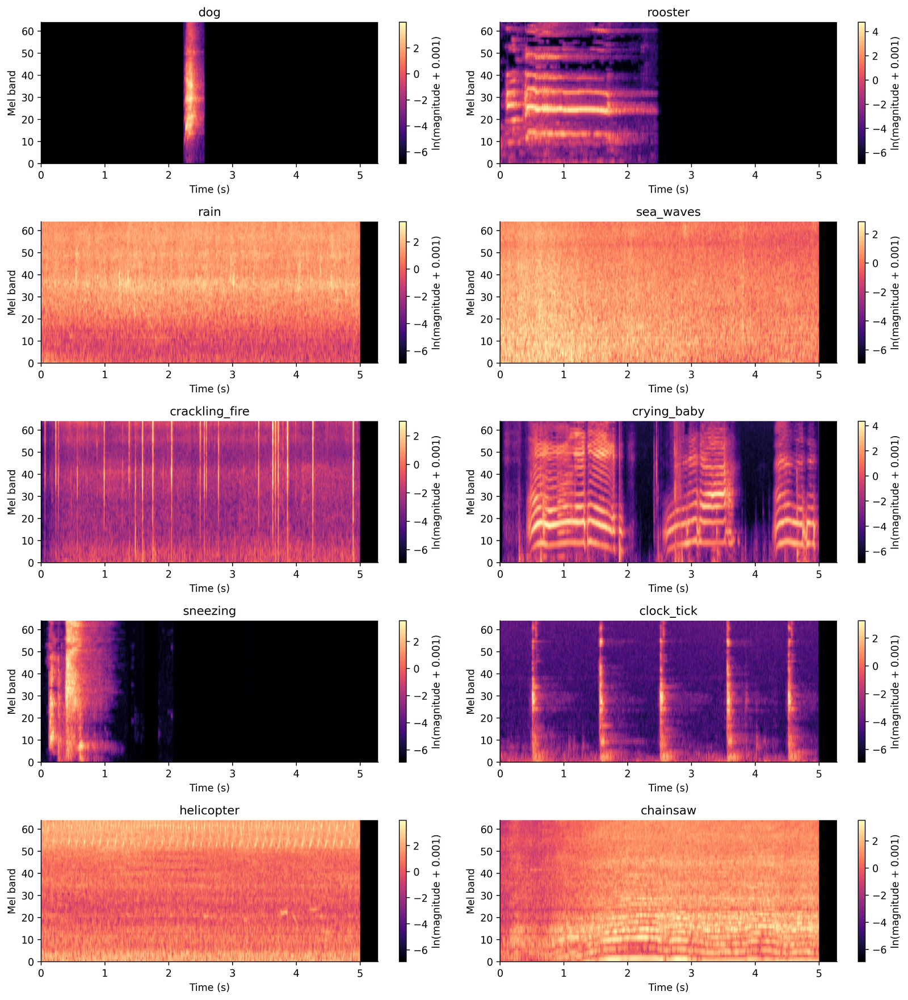

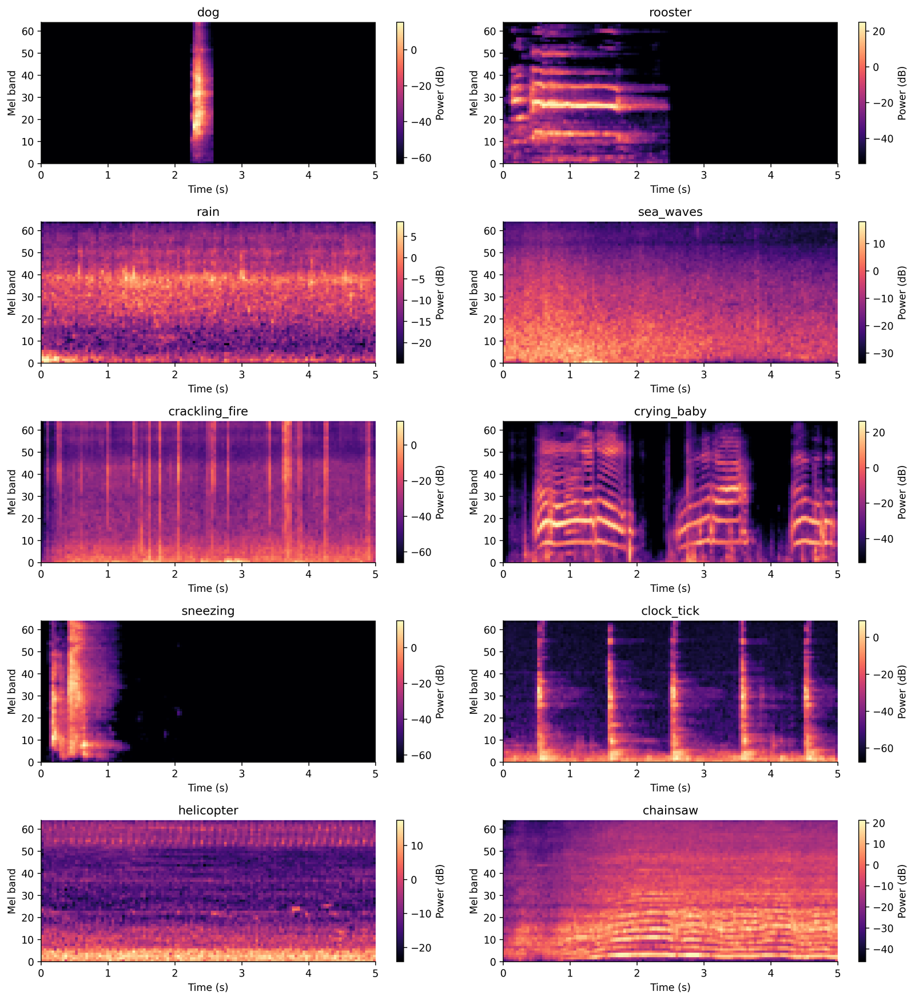

In [7]:
TF_EXTRACTOR = r'''
import os
os.environ['CUDA_VISIBLE_DEVICES']='-1'
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'
import sys,json
from pathlib import Path
import numpy as np
import tensorflow as tf
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
request=json.loads(Path(sys.argv[1]).read_text())
folder=Path(request['backbone'])
if (folder/'saved_model.pb').exists():
    model=tf.saved_model.load(str(folder))
else:
    import tensorflow_hub as hub
    model=hub.load('https://tfhub.dev/google/yamnet/1')
    tf.saved_model.save(model,str(folder))
waves=np.load(request['waves'],allow_pickle=False)
pooled=[]; specs=[]
for i,y in enumerate(waves):
    _,embedding,spec=model(tf.convert_to_tensor(y,dtype=tf.float32))
    pooled.append(embedding.numpy().mean(axis=0))
    if i in request['spectrogram_indices']: specs.append(spec.numpy().T)
    if (i+1)%40==0: print('YAMNet frozen extraction',i+1,'/',len(waves),flush=True)
np.savez_compressed(request['output'],embeddings=np.stack(pooled).astype('float32'),
                    filenames=np.array(request['filenames']),spectrograms=np.stack(specs))
print('TensorFlow',tf.__version__,flush=True)
'''


def directory_digest(folder):
    return identity({p.relative_to(folder).as_posix():sha(p) for p in sorted(Path(folder).rglob('*')) if p.is_file()})


def get_efficientnet():
    path=ASSETS/'backbones/efficientnet_backbone.pt'
    if path.exists():
        net=efficientnet_b0(weights=None); net.classifier=nn.Identity()
        net.load_state_dict(safe_load(path),strict=True)
    else:
        net=efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1); net.classifier=nn.Identity()
        path.parent.mkdir(parents=True,exist_ok=True); torch.save(net.state_dict(),path)
    return net.requires_grad_(False).eval()


def feature_contract(df,name):
    backbone=(directory_digest(ASSETS/'backbones/yamnet') if name=='yamnet_transfer'
              else sha(ASSETS/'backbones/efficientnet_backbone.pt'))
    return dict(model=name,files=df[['filename','sha256']].to_dict('records'),backbone=backbone,
        input=dict(sample_rate=16000,samples=80000,mono='mean',resample='soxr_hq'),
        mel=(MEL_CFG if name=='efficientnet_b0_mel' else dict(frontend='official YAMNet',pooling='mean')),
        dimension=RECIPES[name]['dimension'])


def load_features(df,name,recompute=False,yamnet_python=None):
    folder=ASSETS/'features'; folder.mkdir(parents=True,exist_ok=True)
    path=folder/f'{name}.npz'; record=path.with_suffix('.json')
    if path.exists() and record.exists() and not recompute:
        meta=read(record)
        assert meta['sha256']==sha(path),'Frozen feature checksum mismatch'
        assert meta['contract']==feature_contract(df,name),'Feature/data/backbone contract changed; recompute features'
        with np.load(path,allow_pickle=False) as z:
            assert z['filenames'].tolist()==df.filename.tolist(),'Feature order mismatch'
            values=z['embeddings'].copy()
        assert values.shape==(400,RECIPES[name]['dimension']) and np.isfinite(values).all()
        print(TITLES[name],': verified cached frozen features',values.shape)
        return values
    start=time.perf_counter()
    if name=='efficientnet_b0_mel':
        net=get_efficientnet().to(DEVICE); outputs=[]
        with torch.inference_mode():
            for begin in range(0,len(df),8):
                mels=np.stack([mel_for_efficientnet(waveform(ASSETS/'audio'/fn)) for fn in df.filename.iloc[begin:begin+8]])
                outputs.append(net(efficientnet_input(mels).to(DEVICE)).cpu().numpy())
        values=np.concatenate(outputs).astype('float32'); del net
        if DEVICE.type=='cuda': torch.cuda.empty_cache()
    else:
        waves=np.stack([waveform(ASSETS/'audio'/fn) for fn in df.filename])
        wave_path=ROOT/'yamnet_waves.npy'; np.save(wave_path,waves,allow_pickle=False)
        worker=ROOT/'yamnet_extract_worker.py'; worker.write_text(TF_EXTRACTOR,encoding='utf-8')
        request=ROOT/'yamnet_request.json'
        dump(request,dict(backbone=str(ASSETS/'backbones/yamnet'),waves=str(wave_path),filenames=df.filename.tolist(),
                          output=str(path),spectrogram_indices=[]))
        # The empty spectrogram list is handled as a separate visualization request.
        worker.write_text(TF_EXTRACTOR.replace('spectrograms=np.stack(specs)','spectrograms=np.array(specs)'),encoding='utf-8')
        subprocess.run([str(yamnet_python or sys.executable),str(worker),str(request)],check=True,timeout=1800,
                       creationflags=getattr(subprocess,'CREATE_NO_WINDOW',0))
        with np.load(path,allow_pickle=False) as z: values=z['embeddings'].copy()
        wave_path.unlink(missing_ok=True)
    assert values.shape==(400,RECIPES[name]['dimension']) and np.isfinite(values).all()
    np.savez_compressed(path,embeddings=values,filenames=df.filename.to_numpy(dtype=str))
    dump(record,dict(sha256=sha(path),contract=feature_contract(df,name),seconds=time.perf_counter()-start,
                     labels_used=False,backbone_frozen=True))
    print(TITLES[name],': extracted frozen features',values.shape)
    return values


def frontend_figures(df,examples,yamnet_python=None):
    path=ASSETS/'features/frontend_examples.npz'
    names=[r.filename for r in examples]
    if path.exists():
        with np.load(path,allow_pickle=False) as z:
            assert z['filenames'].tolist()==names
            yam_mels=z['yamnet_mels'].copy()
    else:
        waves=np.stack([waveform(ASSETS/'audio'/name) for name in names])
        wave_path=ROOT/'yamnet_examples.npy'; np.save(wave_path,waves,allow_pickle=False)
        worker=ROOT/'yamnet_extract_worker.py'; worker.write_text(TF_EXTRACTOR,encoding='utf-8')
        request=ROOT/'yamnet_request.json'; result=ROOT/'yamnet_examples_output.npz'
        dump(request,dict(backbone=str(ASSETS/'backbones/yamnet'),waves=str(wave_path),filenames=names,
                          output=str(result),spectrogram_indices=list(range(10))))
        subprocess.run([str(yamnet_python or sys.executable),str(worker),str(request)],check=True,timeout=600,
                       creationflags=getattr(subprocess,'CREATE_NO_WINDOW',0))
        with np.load(result,allow_pickle=False) as z: yam_mels=z['spectrograms'].copy()
        np.savez_compressed(path,filenames=np.array(names),yamnet_mels=yam_mels)
        wave_path.unlink(missing_ok=True); result.unlink(missing_ok=True)
    for name in NAMES:
        fig,axes=plt.subplots(5,2,figsize=(13,14))
        for i,(row,ax) in enumerate(zip(examples,axes.flat)):
            mel=yam_mels[i] if name=='yamnet_transfer' else mel_for_efficientnet(waveform(ASSETS/'audio'/row.filename))
            im=ax.imshow(mel,origin='lower',aspect='auto',extent=(0,mel.shape[1]*.01 if name=='yamnet_transfer' else 5,0,64),cmap='magma')
            ax.set(title=row.category,xlabel='Time (s)',ylabel='Mel band')
            fig.colorbar(im,ax=ax,label='ln(magnitude + 0.001)' if name=='yamnet_transfer' else 'Power (dB)')
        save(fig,f'{name}_frontend_examples',TITLES[name]+' үшін нақты frontend мысалдары','data')

features={}
for name in NAMES:
    features[name]=load_features(df,name,RECOMPUTE_FEATURES,TF_PYTHON)
frontend_figures(df,examples,TF_PYTHON)


## 8 Head оқыту алгоритмі

Әр fold үшін scaler **тек train** арқылы fit жасалады:

$$z_j=(h_j-\mu_{train,j})/\max(\sigma_{train,j},10^{-6}).$$

Шығын — logits қабылдайтын CrossEntropyLoss. Softmax loss алдында қолданылмайды.
AdamW, validation бойынша ReduceLROnPlateau және early stopping қолданылады.
Ең жақсы checkpoint minimum validation loss арқылы сақталады, test көрсеткішімен таңдалмайды.
Seed 42; batch 16; dropout 0.2. YAMNet lr=0.001, max 160 epoch, patience 25;
EfficientNet lr=0.002, max 120 epoch, patience 20; weight decay екеуінде 0.001.

Бұл бұрын бекітілген екі модельдік recipe. Оптимизатор іздеу бюджеті теңестірілген ablation емес.
Келесі екі ұяшық барлық head-ты оқытып болған соң ғана test бағалау басталады.


In [8]:
class TransferHead(nn.Module):
    def __init__(self,dimension):
        super().__init__(); self.net=nn.Sequential(nn.Dropout(.2),nn.Linear(dimension,10))
    def forward(self,x): return self.net(x)


def run_id(name,fold):
    return f'{name}_fixed' if fold==5 else f'{name}_fold{fold}'


def train_one(df,features,name,fold,mode='retrain'):
    recipe=RECIPES[name]; rid=run_id(name,fold)
    checkpoint=OUT/f'models/{rid}.pt'; history_path=OUT/f'history/{rid}.csv'; meta_path=history_path.with_suffix('.json')
    train,val,test=split_masks(df,fold)
    data_id=identity(df[['filename','sha256']].to_dict('records'))
    if mode=='use_trained':
        meta=read(meta_path)
        assert sha(checkpoint)==meta['checkpoint_sha256'] and sha(history_path)==meta['history_sha256']
        payload=safe_load(checkpoint)
        assert payload['dataset_identity']==data_id and payload['recipe']==recipe and payload['test_fold']==fold
        assert payload['feature_sha256']==sha(ASSETS/f'features/{name}.npz')
        np.testing.assert_allclose(payload['mean'],features[train].mean(0,dtype=np.float64),rtol=1e-12,atol=1e-12)
        np.testing.assert_allclose(payload['std'],np.maximum(features[train].std(0,dtype=np.float64),1e-6),rtol=1e-12,atol=1e-12)
        print('Loaded trained:',rid,'epoch',meta['best_epoch'])
        return meta
    if mode!='retrain': raise ValueError('Choose retrain or use_trained')
    seed_all(42)
    mean=features[train].mean(0,dtype=np.float64); std=np.maximum(features[train].std(0,dtype=np.float64),1e-6)
    norm=((features-mean)/std).astype(np.float32)
    x=torch.from_numpy(norm); y=torch.tensor(df.class_index.to_numpy(),dtype=torch.long)
    generator=torch.Generator().manual_seed(42)
    train_loader=DataLoader(TensorDataset(x[train],y[train]),batch_size=recipe['batch_size'],shuffle=True,generator=generator)
    val_loader=DataLoader(TensorDataset(x[val],y[val]),batch_size=16,shuffle=False)
    model=TransferHead(recipe['dimension']).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=recipe['lr'],weight_decay=recipe['weight_decay'])
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,patience=5,factor=.5)
    criterion=nn.CrossEntropyLoss(); history=[]; best=float('inf'); stale=0; start=time.perf_counter()
    for epoch in range(1,recipe['epochs']+1):
        row=dict(epoch=epoch,learning_rate=optimizer.param_groups[0]['lr'])
        for phase,loader in [('train',train_loader),('validation',val_loader)]:
            training=phase=='train'; model.train(training); loss_sum=0.; correct=0; total=0
            with torch.set_grad_enabled(training):
                for xb,yb in loader:
                    xb,yb=xb.to(DEVICE),yb.to(DEVICE)
                    if training: optimizer.zero_grad(set_to_none=True)
                    logits=model(xb); loss=criterion(logits,yb)
                    assert torch.isfinite(loss)
                    if training: loss.backward(); optimizer.step()
                    loss_sum+=float(loss.detach())*len(yb); correct+=int((logits.argmax(1)==yb).sum()); total+=len(yb)
            row[f'{phase}_loss']=loss_sum/total; row[f'{phase}_accuracy']=correct/total
        history.append(row); scheduler.step(row['validation_loss'])
        if row['validation_loss']<best:
            best=row['validation_loss']; stale=0
            payload=dict(schema='soundsense_two_models_v1',name=name,dimension=recipe['dimension'],labels=LABELS,
                state_dict={k:v.detach().cpu().clone() for k,v in model.state_dict().items()},mean=mean.tolist(),std=std.tolist(),
                test_fold=fold,validation_fold=fold-1 or 5,train_folds=sorted(df.loc[train,'fold'].unique().tolist()),
                best_epoch=epoch,validation_loss=best,recipe=recipe,seed=42,fit_count=240,
                dataset_identity=data_id,feature_sha256=sha(ASSETS/f'features/{name}.npz'),
                backbone_frozen=True,trained_all_400=False)
            torch.save(payload,checkpoint)
        else: stale+=1
        if epoch==1 or epoch%20==0:
            print(f'{rid}: epoch {epoch:3d} train={row["train_accuracy"]:.3f} val={row["validation_accuracy"]:.3f} val_loss={row["validation_loss"]:.4f}')
        if stale>=recipe['patience']: break
    pd.DataFrame(history).to_csv(history_path,index=False)
    payload=safe_load(checkpoint)
    meta=dict(model=name,fold=fold,epochs=len(history),best_epoch=payload['best_epoch'],
              validation_loss=payload['validation_loss'],training_seconds=time.perf_counter()-start,
              head_parameters=sum(p.numel() for p in model.parameters()),checkpoint_bytes=checkpoint.stat().st_size,
              checkpoint_sha256=sha(checkpoint),history_sha256=sha(history_path),seed=42,device=str(DEVICE))
    dump(meta_path,meta)
    return meta


def train_model(df,features,name,mode='retrain'):
    # No test scores are used during training or checkpoint selection.
    metas=[train_one(df,features,name,fold,mode) for fold in [5,1,2,3,4]]
    pd.DataFrame(metas).to_csv(OUT/f'tables/{name}_training_summary.csv',index=False)
    print(pd.DataFrame(metas)[['fold','epochs','best_epoch','validation_loss','training_seconds']].to_string(index=False))
    return metas


In [9]:
training_yamnet=train_model(df,features['yamnet_transfer'],'yamnet_transfer',RUN_MODE)


yamnet_transfer_fixed: epoch   1 train=0.463 val=0.725 val_loss=1.2611
yamnet_transfer_fixed: epoch  20 train=0.983 val=0.938 val_loss=0.1117
yamnet_transfer_fixed: epoch  40 train=0.996 val=0.963 val_loss=0.0780
yamnet_transfer_fixed: epoch  60 train=1.000 val=0.988 val_loss=0.0537
yamnet_transfer_fixed: epoch  80 train=1.000 val=0.975 val_loss=0.0551
yamnet_transfer_fold1: epoch   1 train=0.417 val=0.738 val_loss=1.0825
yamnet_transfer_fold1: epoch  20 train=1.000 val=0.963 val_loss=0.1082
yamnet_transfer_fold1: epoch  40 train=0.996 val=0.963 val_loss=0.0924
yamnet_transfer_fold1: epoch  60 train=1.000 val=0.975 val_loss=0.0845
yamnet_transfer_fold2: epoch   1 train=0.421 val=0.750 val_loss=1.0357
yamnet_transfer_fold2: epoch  20 train=0.996 val=0.963 val_loss=0.1161
yamnet_transfer_fold2: epoch  40 train=1.000 val=1.000 val_loss=0.0755
yamnet_transfer_fold3: epoch   1 train=0.433 val=0.738 val_loss=1.1222
yamnet_transfer_fold3: epoch  20 train=0.988 val=0.975 val_loss=0.1140
yamnet

In [10]:
training_efficientnet=train_model(df,features['efficientnet_b0_mel'],'efficientnet_b0_mel',RUN_MODE)


efficientnet_b0_mel_fixed: epoch   1 train=0.658 val=0.863 val_loss=0.5106
efficientnet_b0_mel_fixed: epoch  20 train=1.000 val=0.838 val_loss=0.3409
efficientnet_b0_mel_fixed: epoch  40 train=1.000 val=0.850 val_loss=0.3314
efficientnet_b0_mel_fold1: epoch   1 train=0.625 val=0.863 val_loss=0.5039
efficientnet_b0_mel_fold1: epoch  20 train=1.000 val=0.900 val_loss=0.3274
efficientnet_b0_mel_fold2: epoch   1 train=0.688 val=0.863 val_loss=0.4700
efficientnet_b0_mel_fold2: epoch  20 train=1.000 val=0.912 val_loss=0.3523
efficientnet_b0_mel_fold3: epoch   1 train=0.662 val=0.875 val_loss=0.4254
efficientnet_b0_mel_fold3: epoch  20 train=1.000 val=0.875 val_loss=0.2936
efficientnet_b0_mel_fold4: epoch   1 train=0.679 val=0.863 val_loss=0.4781
efficientnet_b0_mel_fold4: epoch  20 train=1.000 val=0.887 val_loss=0.4322
 fold  epochs  best_epoch  validation_loss  training_seconds
    5      56          36         0.330704          8.813803
    1      23           3         0.322923          3

## 9 Нақты test және бес fold OOF бағалауы

CV: test K, validation K−1 (K=1 үшін validation 5), қалған үш fold train. Әр клипке оны train
ретінде көрмеген модель бір OOF болжам береді. Fixed fold 5 checkpoint қайта қолданылады.
Нәтижесінде әр жүйеге 80 fixed test және 400 OOF болжам сақталады.

$$Accuracy=N_{correct}/N,\qquad F1=2PR/(P+R),\qquad MacroF1=\tfrac1{10}\sum_{c=1}^{10}F1_c.$$

Шатасу матрицасында жол — нақты, баған — болжанған санат. Қалыпталған диагональ — recall.
ROC және PR one-vs-rest түрінде есептеледі. Macro AP — sklearn average precision, трапециялық
PR AUC емес. Интерполяция график көрсету үшін ғана қолданылады. Fold SD — confidence interval емес.


In [11]:
def load_head(name,fold=5):
    payload=safe_load(OUT/f'models/{run_id(name,fold)}.pt')
    assert payload['schema']=='soundsense_two_models_v1' and payload['name']==name and payload['labels']==LABELS
    assert payload['dimension']==RECIPES[name]['dimension']
    net=TransferHead(payload['dimension']).eval(); net.load_state_dict(payload['state_dict'],strict=True)
    return net,payload


def score(frame):
    y=frame.true_index.to_numpy(); p=frame[[f'prob_{x}' for x in LABELS]].to_numpy(); pred=p.argmax(1)
    assert frame.filename.is_unique and np.isfinite(p).all() and np.allclose(p.sum(1),1,atol=1e-5)
    assert np.array_equal(pred,frame.predicted_index)
    report=classification_report(y,pred,labels=range(10),target_names=LABELS,zero_division=0,output_dict=True)
    return dict(count=len(frame),correct=int((y==pred).sum()),accuracy=float(accuracy_score(y,pred)),
        macro_f1=float(f1_score(y,pred,average='macro')),macro_roc_auc=float(roc_auc_score(y,p,multi_class='ovr',average='macro')),
        macro_ap=float(np.mean([average_precision_score(y==i,p[:,i]) for i in range(10)])),classification_report=report)


def predict_fold(df,features,name,fold):
    net,payload=load_head(name,fold); _,_,test=split_masks(df,fold)
    assert fold not in payload['train_folds'] and payload['validation_fold'] not in payload['train_folds']
    x=((features[test]-np.array(payload['mean']))/np.array(payload['std'])).astype('float32')
    with torch.inference_mode(): p=net(torch.from_numpy(x)).softmax(1).numpy()
    frame=df.loc[test,['filename','fold','src_file','category','class_index']].reset_index(drop=True).rename(columns={'category':'true_label','class_index':'true_index'})
    frame['predicted_index']=p.argmax(1); frame['predicted_label']=[LABELS[i] for i in p.argmax(1)]
    frame['confidence']=p.max(1)
    for i,label in enumerate(LABELS): frame[f'prob_{label}']=p[:,i]
    return frame


def macro_curves(frame):
    y=frame.true_index.to_numpy(); p=frame[[f'prob_{x}' for x in LABELS]].to_numpy(); grid=np.linspace(0,1,501)
    rocs=[]; prs=[]
    for i in range(10):
        fpr,tpr,_=roc_curve(y==i,p[:,i]); precision,recall,_=precision_recall_curve(y==i,p[:,i])
        rocs.append(np.interp(grid,fpr,tpr)); prs.append(np.interp(grid,recall[::-1],precision[::-1]))
    return grid,np.mean(rocs,0),np.mean(prs,0)


def plot_scores(name,run,frame,metrics):
    stem=f'{name}_{run}'; y=frame.true_index.to_numpy(); pred=frame.predicted_index.to_numpy()
    p=frame[[f'prob_{x}' for x in LABELS]].to_numpy(); matrix=confusion_matrix(y,pred,labels=range(10))
    for normalized in [False,True]:
        values=matrix/matrix.sum(1,keepdims=True) if normalized else matrix
        suffix='_normalized' if normalized else ''
        pd.DataFrame(values,index=LABELS,columns=LABELS).to_csv(OUT/f'metrics/{stem}_confusion{suffix}.csv')
        fig,ax=plt.subplots(figsize=(9,8)); im=ax.imshow(values,cmap='Blues',vmin=0,vmax=1 if normalized else None)
        ax.set(xticks=range(10),yticks=range(10),xticklabels=LABELS,yticklabels=LABELS,xlabel='Predicted class',ylabel='True class',
               title=f'{TITLES[name]} {run}: {metrics["correct"]}/{metrics["count"]} correct')
        plt.setp(ax.get_xticklabels(),rotation=45,ha='right')
        for i in range(10):
            for j in range(10):
                ax.text(j,i,f'{values[i,j]:.2f}' if normalized else str(values[i,j]),ha='center',va='center',fontsize=8,
                        color='white' if values[i,j]>values.max()/2 else 'black')
        fig.colorbar(im,ax=ax); save(fig,f'{stem}_confusion{suffix}','Қалыпталған шатасу матрицасы' if normalized else 'Қателер саны көрсетілген шатасу матрицасы')
    fig,ax=plt.subplots(figsize=(10,4)); ax.bar(LABELS,[metrics['classification_report'][x]['f1-score'] for x in LABELS],color=COLORS[name])
    ax.set(ylim=(0,1.05),ylabel='F1',title=f'{TITLES[name]} {run}: per-class F1'); plt.setp(ax.get_xticklabels(),rotation=40,ha='right')
    save(fig,f'{stem}_per_class_f1','Әр санаттың precision және recall теңгерімін көрсететін F1')
    grid,macro_roc,macro_pr=macro_curves(frame)
    for kind in ['roc','precision_recall']:
        fig,ax=plt.subplots(figsize=(8,6)); curve_data={}
        for i,label in enumerate(LABELS):
            if kind=='roc':
                a,b,_=roc_curve(y==i,p[:,i]); value=roc_auc_score(y==i,p[:,i]); ax.plot(a,b,lw=1,label=f'{label}: {value:.3f}')
                curve_data[label]=dict(fpr=a.tolist(),tpr=b.tolist(),auc=float(value))
            else:
                b,a,_=precision_recall_curve(y==i,p[:,i]); value=average_precision_score(y==i,p[:,i]); ax.plot(a,b,lw=1,label=f'{label}: {value:.3f}')
                curve_data[label]=dict(recall=a.tolist(),precision=b.tolist(),average_precision=float(value))
        ax.plot(grid,macro_roc if kind=='roc' else macro_pr,'k--',lw=2,label='Macro interpolation for display')
        if kind=='roc': ax.plot([0,1],[0,1],':',color='gray')
        ax.set(xlabel='False positive rate' if kind=='roc' else 'Recall',ylabel='True positive rate' if kind=='roc' else 'Precision',
               ylim=(0,1.03),title=f'{TITLES[name]} {run}: {kind}'); ax.legend(fontsize=7,loc='lower right' if kind=='roc' else 'lower left')
        save(fig,f'{stem}_{kind}','One versus rest қисықтары macro AP трапециялық PR AUC емес')
        dump(OUT/f'metrics/{stem}_{kind}_curves.json',curve_data)


def evaluation_model(df,features,name):
    frames=[]
    for fold in range(1,6):
        frame=predict_fold(df,features,name,fold); rid=run_id(name,fold)
        frame.to_csv(OUT/f'predictions/{rid}.csv',index=False); frames.append(frame)
        history=pd.read_csv(OUT/f'history/{rid}.csv')
        fig,axes=plt.subplots(1,2,figsize=(11,4))
        for phase in ['train','validation']:
            axes[0].plot(history.epoch,history[f'{phase}_loss'],label=phase)
            axes[1].plot(history.epoch,history[f'{phase}_accuracy'],label=phase)
        axes[0].set(xlabel='Epoch',ylabel='Cross entropy',title=f'{TITLES[name]} fold {fold}: loss')
        axes[1].set(xlabel='Epoch',ylabel='Accuracy',ylim=(0,1.03),title=f'{TITLES[name]} fold {fold}: accuracy')
        for ax in axes: ax.legend()
        save(fig,f'{rid}_training','Train және validation қисықтары test метрикасы емес')
    oof=pd.concat(frames,ignore_index=True)
    assert len(oof)==400 and oof.filename.is_unique and set(oof.filename)==set(df.filename)
    oof.to_csv(OUT/f'predictions/{name}_oof.csv',index=False)
    result={}
    for run,frame in [('fixed',frames[4]),('oof',oof)]:
        metrics=score(frame); result[run]=metrics; dump(OUT/f'metrics/{name}_{run}.json',metrics)
        pd.DataFrame(metrics['classification_report']).T.to_csv(OUT/f'metrics/{name}_{run}_classification_report.csv')
        errors=frame[frame.true_index!=frame.predicted_index]
        errors.to_csv(OUT/f'predictions/{name}_{run}_errors.csv',index=False)
        plot_scores(name,run,frame,metrics)
    per_fold=pd.DataFrame([dict(fold=k+1,**{x:score(f)[x] for x in ['count','correct','accuracy','macro_f1']}) for k,f in enumerate(frames)])
    per_fold.to_csv(OUT/f'tables/{name}_fold_scores.csv',index=False)
    summary=dict(accuracy_mean=float(per_fold.accuracy.mean()),accuracy_sd_sample=float(per_fold.accuracy.std(ddof=1)),
                 macro_f1_mean=float(per_fold.macro_f1.mean()),macro_f1_sd_sample=float(per_fold.macro_f1.std(ddof=1)))
    dump(OUT/f'metrics/{name}_cv_summary.json',summary)
    fig,ax=plt.subplots(figsize=(8,4)); ax.plot(per_fold.fold,per_fold.accuracy,'o-',label='Accuracy'); ax.plot(per_fold.fold,per_fold.macro_f1,'s-',label='Macro F1')
    ax.set(xticks=range(1,6),ylim=(0,1.03),xlabel='Outer test fold',title=TITLES[name]+' OOF folds'); ax.legend()
    save(fig,f'{name}_oof_fold_metrics','Бес fold нәтижесі SD сенімділік интервалы емес')
    print(TITLES[name],json.dumps({run:{k:v for k,v in metric.items() if k!='classification_report'} for run,metric in result.items()},indent=2))
    return result

results={}


YAMNet transfer {
  "fixed": {
    "count": 80,
    "correct": 78,
    "accuracy": 0.975,
    "macro_f1": 0.9739495798319329,
    "macro_roc_auc": 0.9987847222222224,
    "macro_ap": 0.9924145299145298
  },
  "oof": {
    "count": 400,
    "correct": 391,
    "accuracy": 0.9775,
    "macro_f1": 0.9774742973899961,
    "macro_roc_auc": 0.9983541666666668,
    "macro_ap": 0.9920574665569388
  }
}


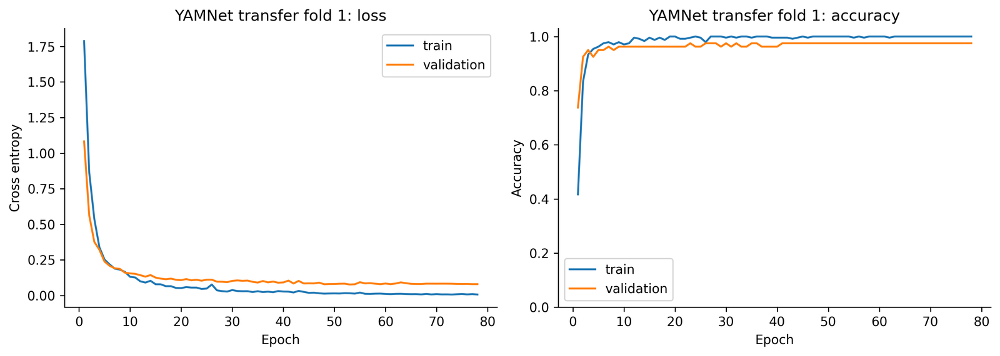

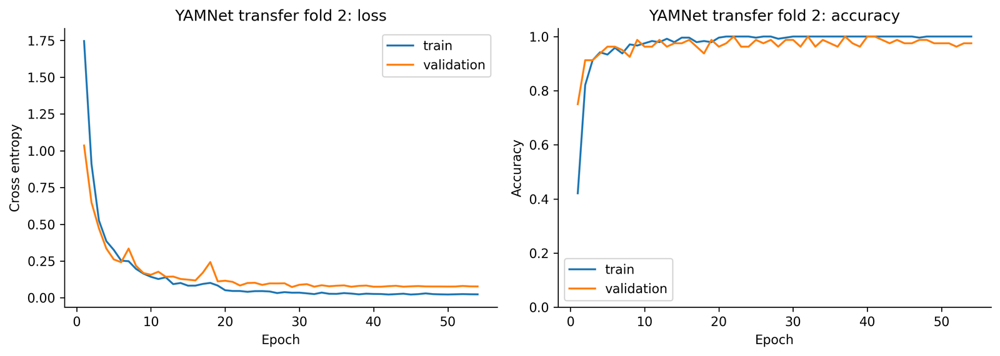

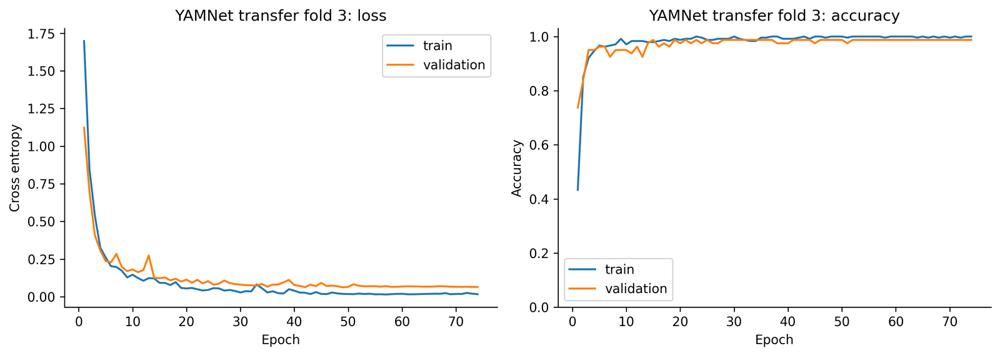

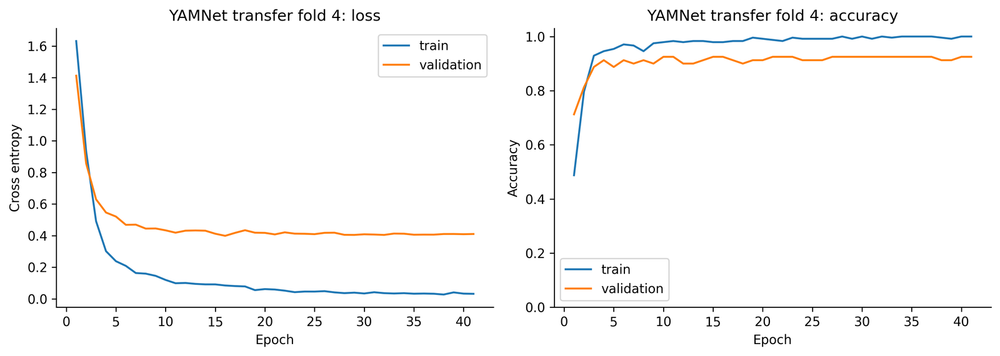

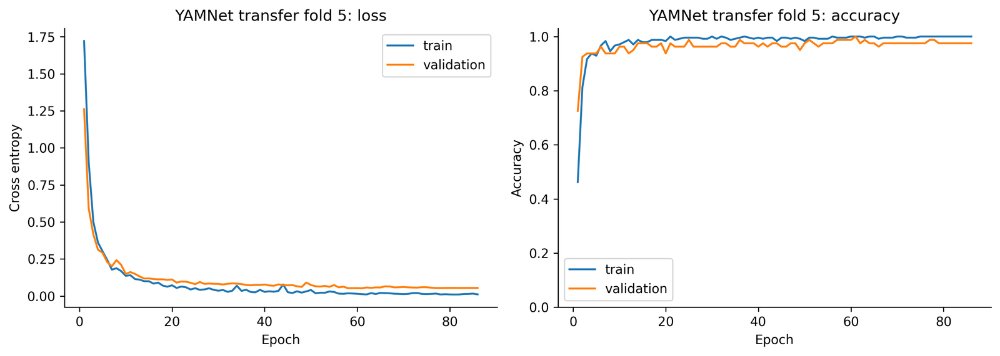

...

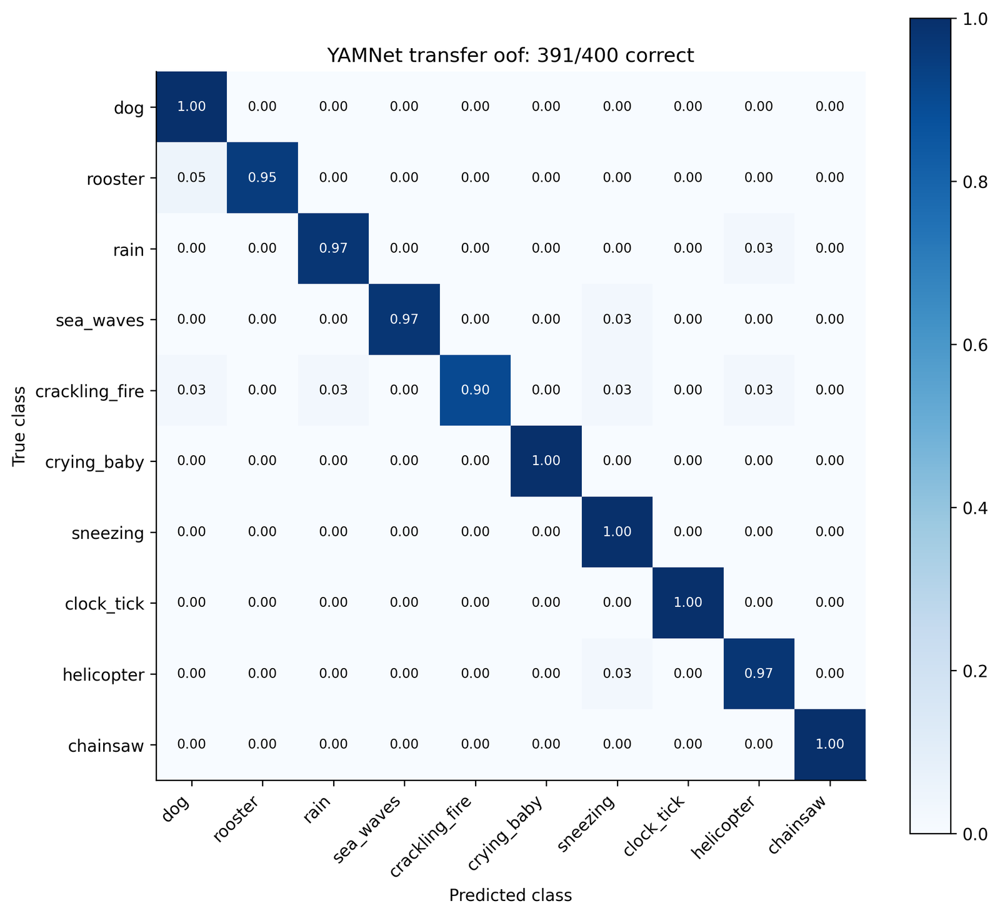

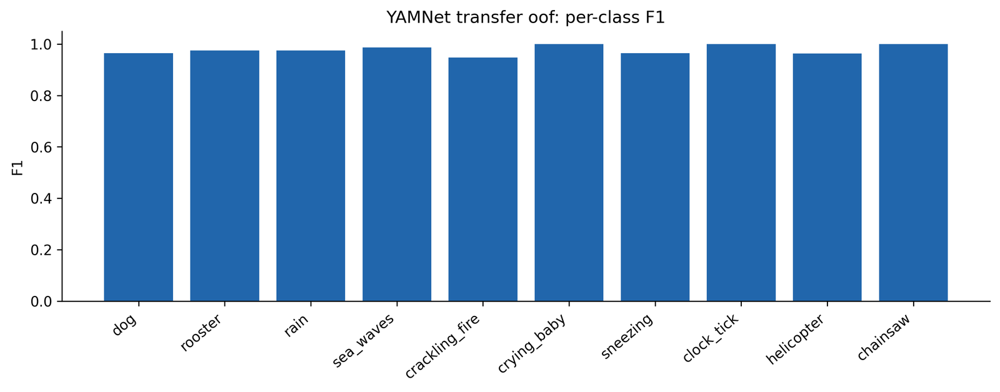

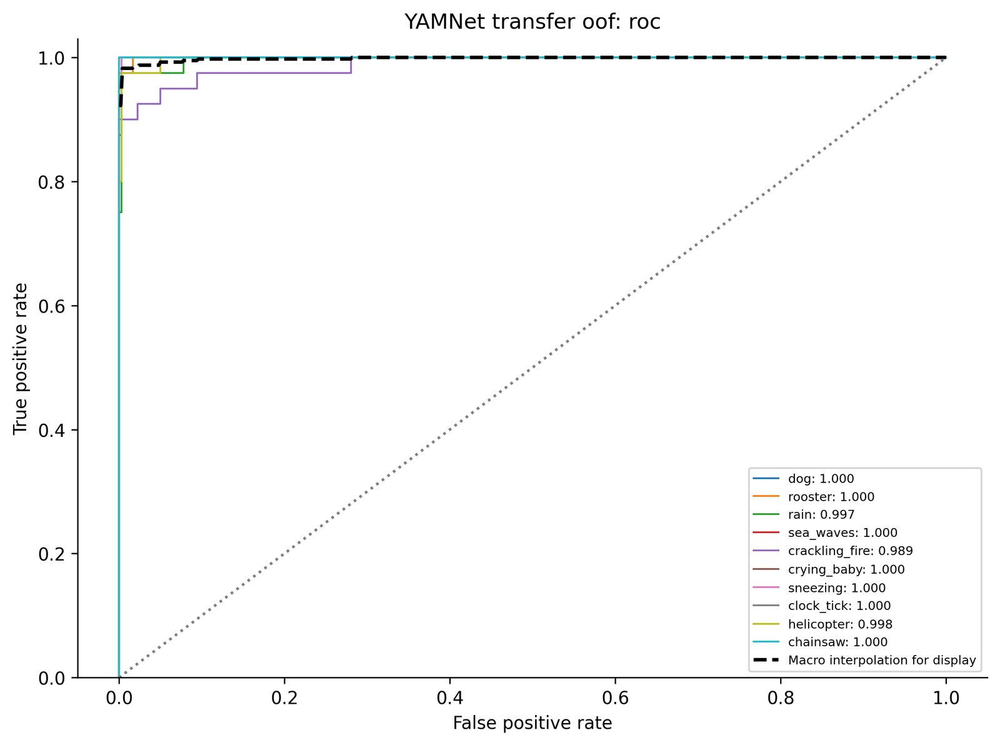

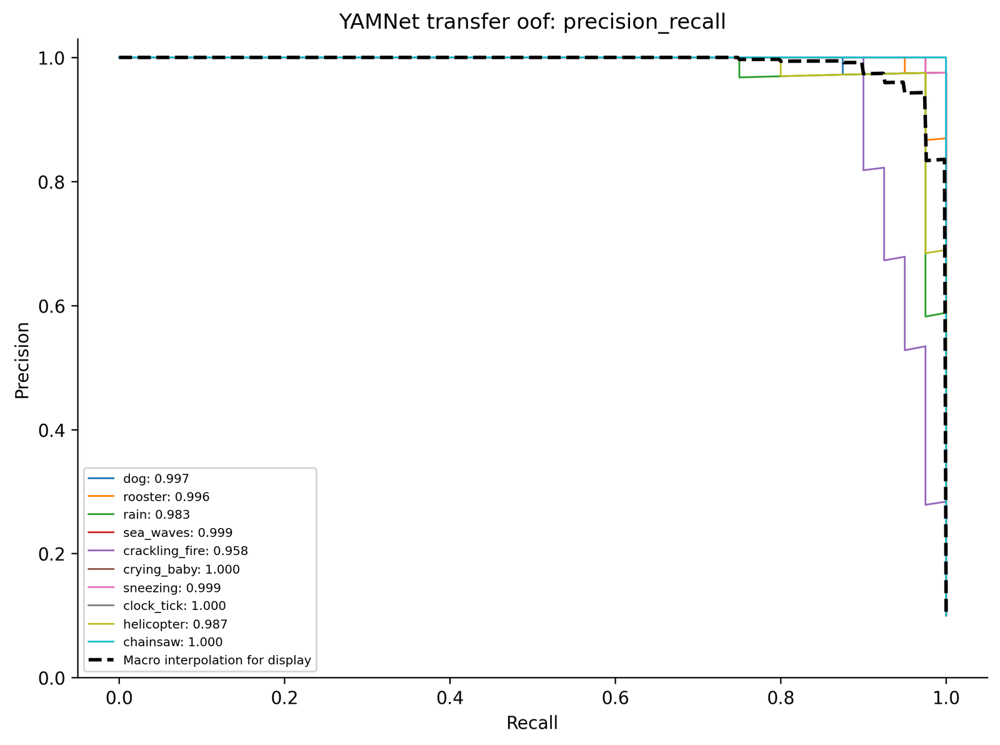

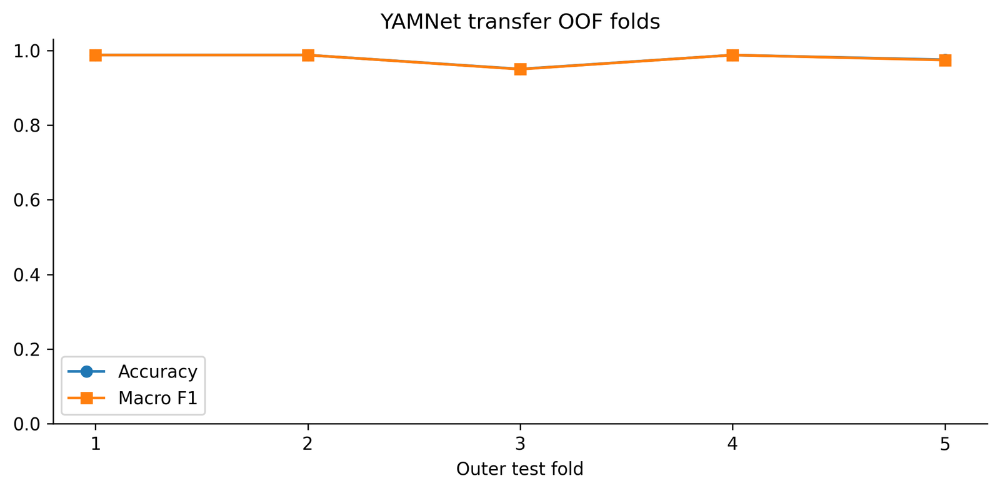

In [12]:
results['yamnet_transfer']=evaluation_model(df,features['yamnet_transfer'],'yamnet_transfer')


EfficientNet-B0 transfer {
  "fixed": {
    "count": 80,
    "correct": 73,
    "accuracy": 0.9125,
    "macro_f1": 0.9114234114698512,
    "macro_roc_auc": 0.9921875,
    "macro_ap": 0.9544282106782106
  },
  "oof": {
    "count": 400,
    "correct": 354,
    "accuracy": 0.885,
    "macro_f1": 0.8848902425528162,
    "macro_roc_auc": 0.9915416666666668,
    "macro_ap": 0.944528966426488
  }
}


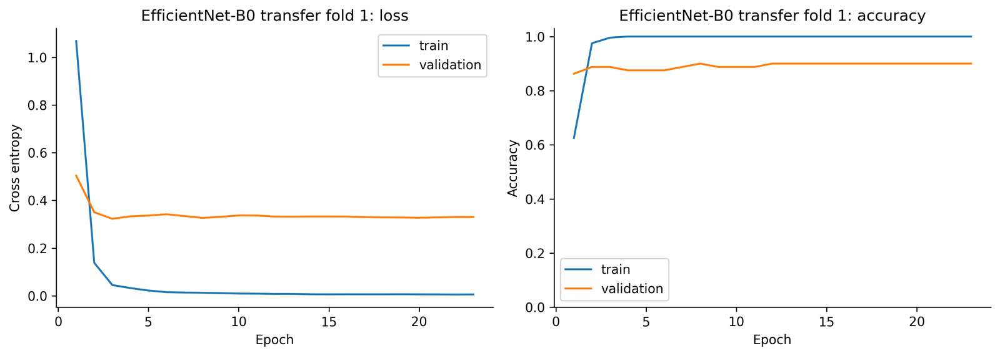

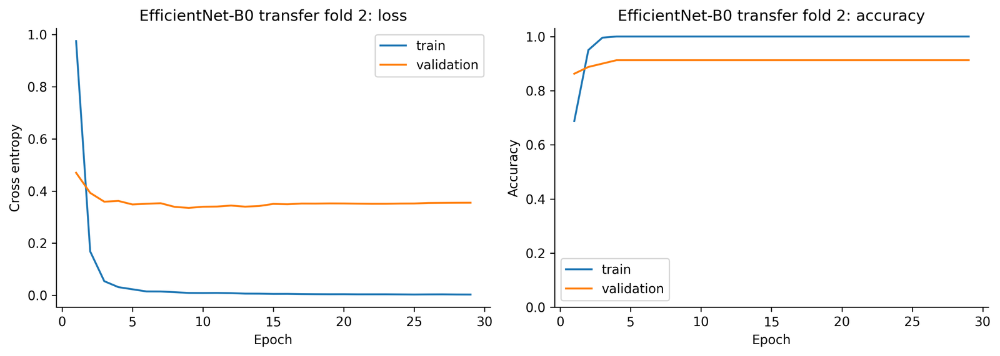

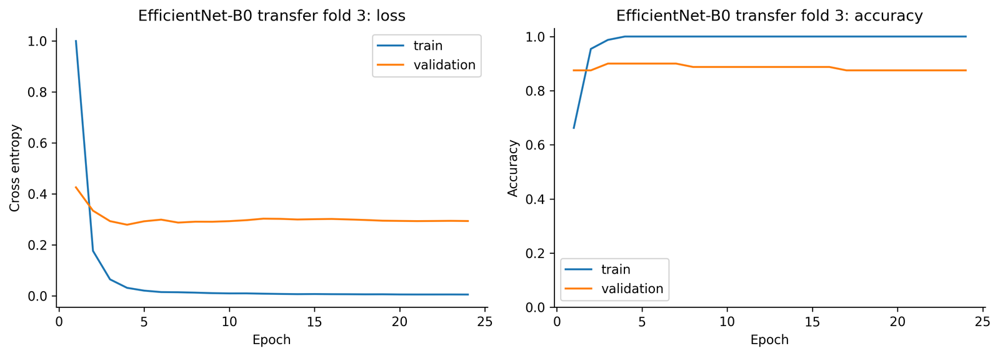

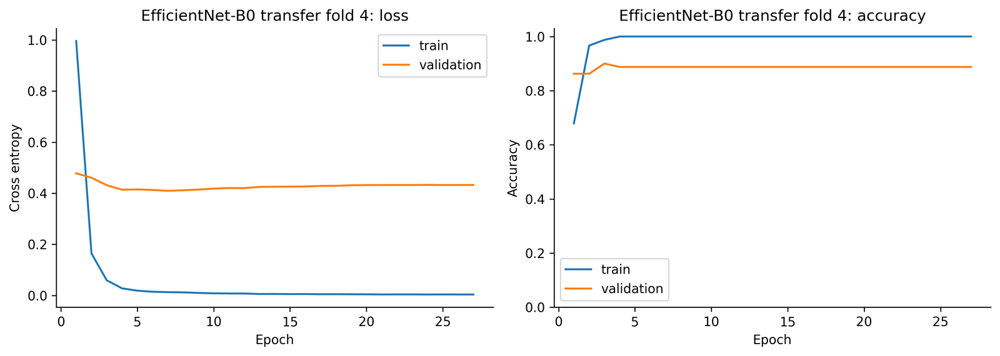

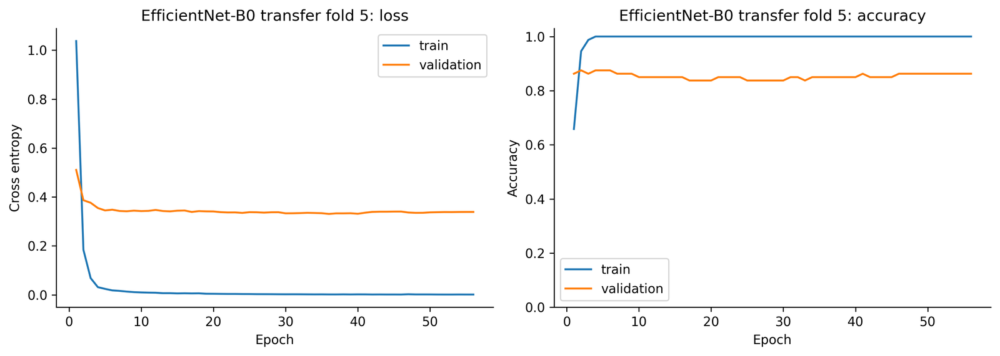

...

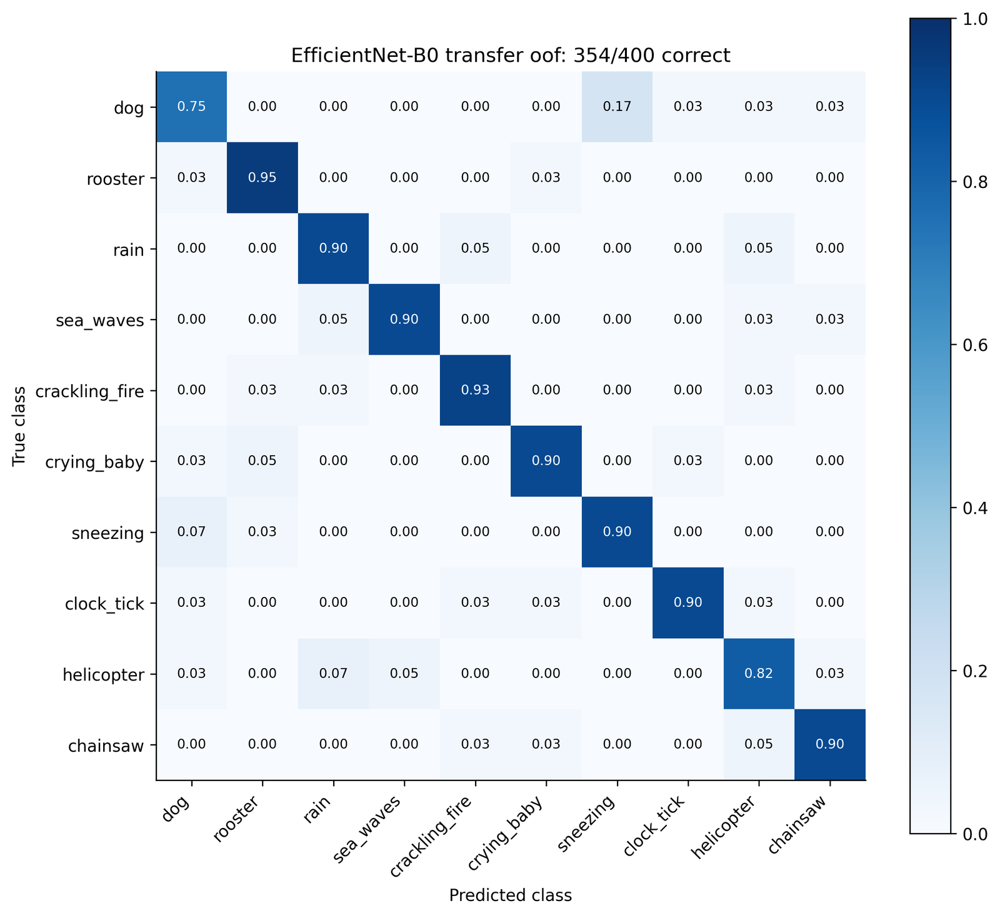

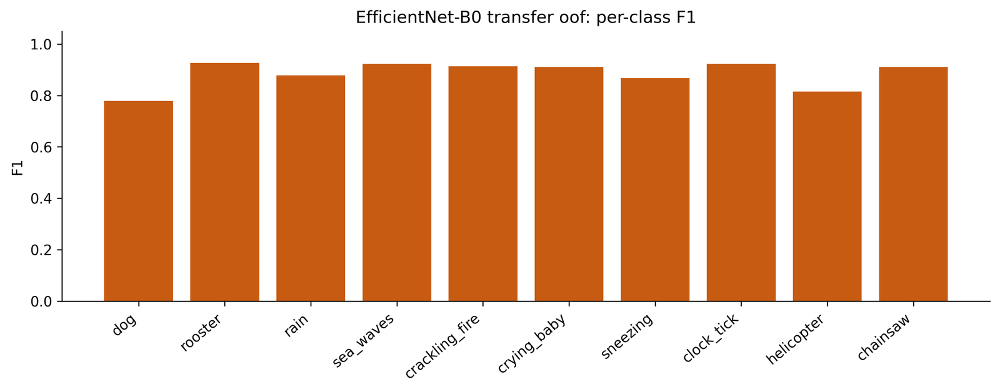

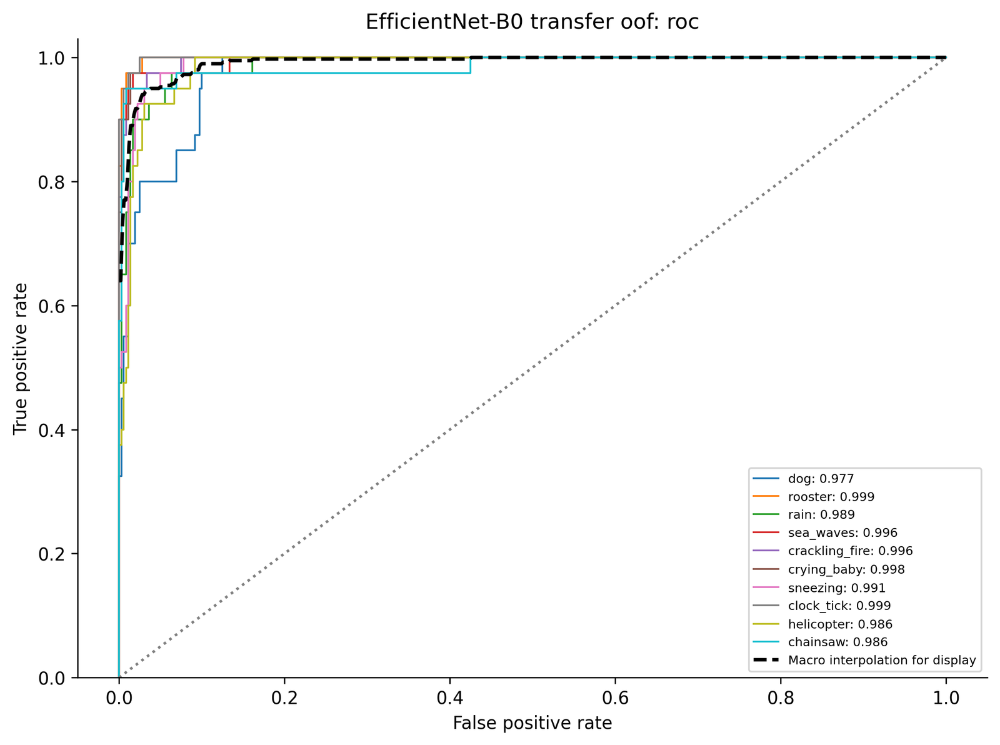

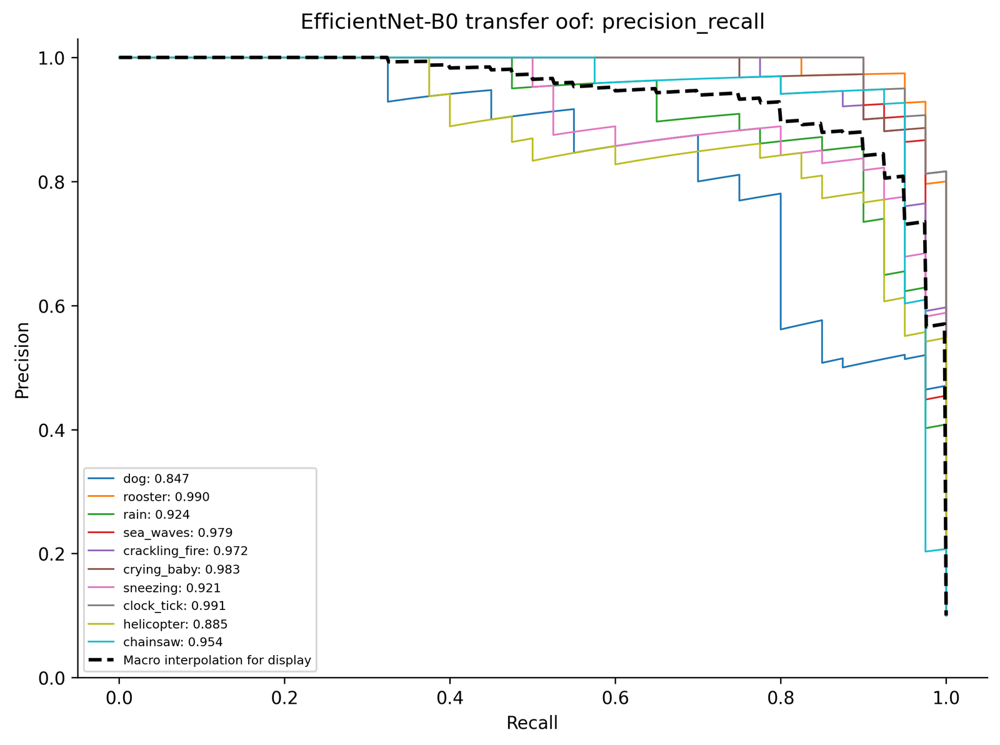

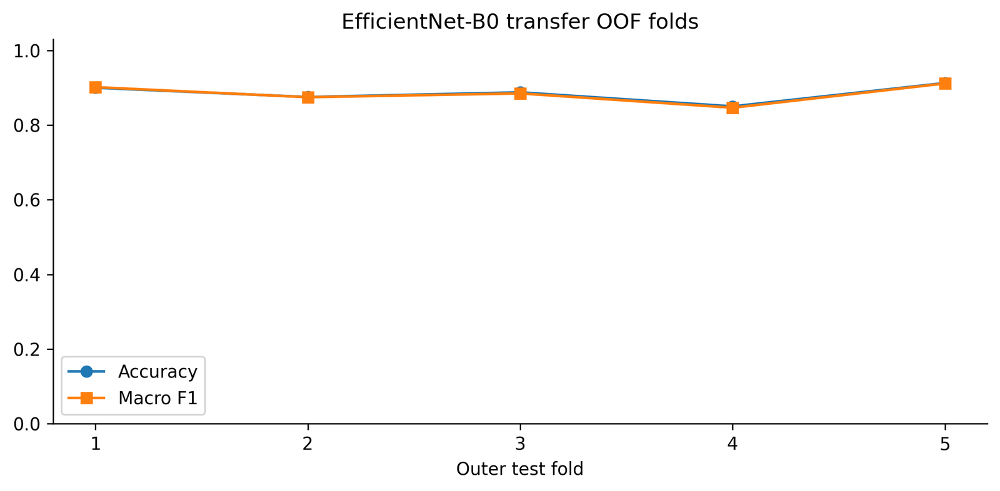

In [13]:
results['efficientnet_b0_mel']=evaluation_model(df,features['efficientnet_b0_mel'],'efficientnet_b0_mel')


## 10 Екі жүйені тікелей салыстыру

Негізгі метрикалар, әр санат F1, macro ROC/PR, бірдей fold нәтижелері, train қисықтары,
paired correctness, score confidence, reliability және head ресурстары көрсетіледі.
Қате мысалдар файл атауымен берілген. Барлық қате CSV-де сақталады; waveform суретінде
алғашқы алтауы ғана көрсетіледі. Reliability калибрлеу әдісін үйретпейді.


              model evaluation  count  correct  accuracy  macro_f1  macro_roc_auc  macro_ap
    yamnet_transfer      fixed     80       78    0.9750  0.973950       0.998785  0.992415
efficientnet_b0_mel      fixed     80       73    0.9125  0.911423       0.992188  0.954428
    yamnet_transfer        oof    400      391    0.9775  0.977474       0.998354  0.992057
efficientnet_b0_mel        oof    400      354    0.8850  0.884890       0.991542  0.944529


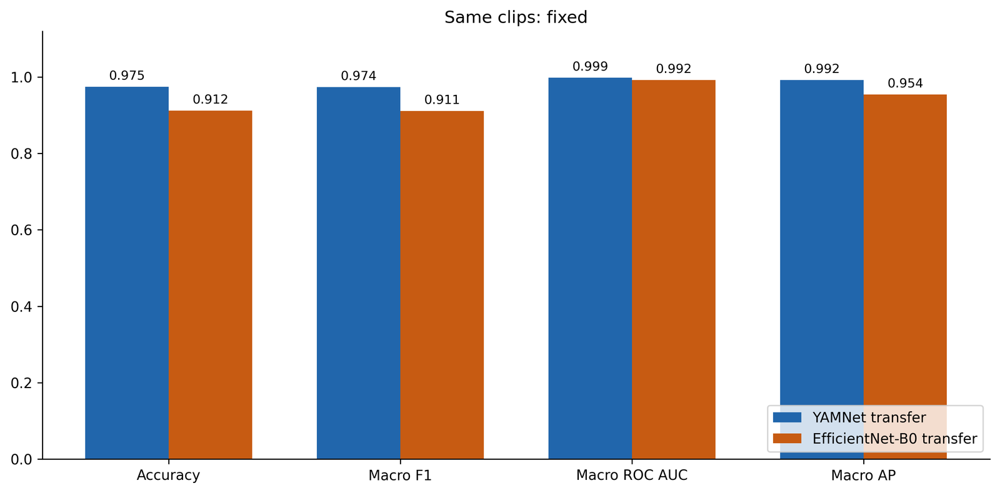

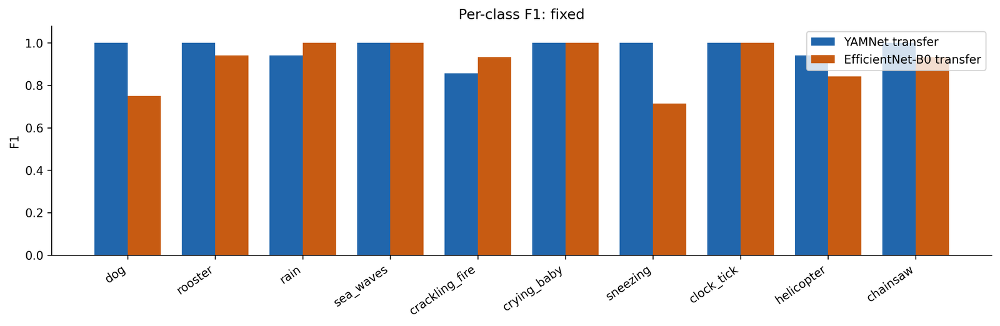

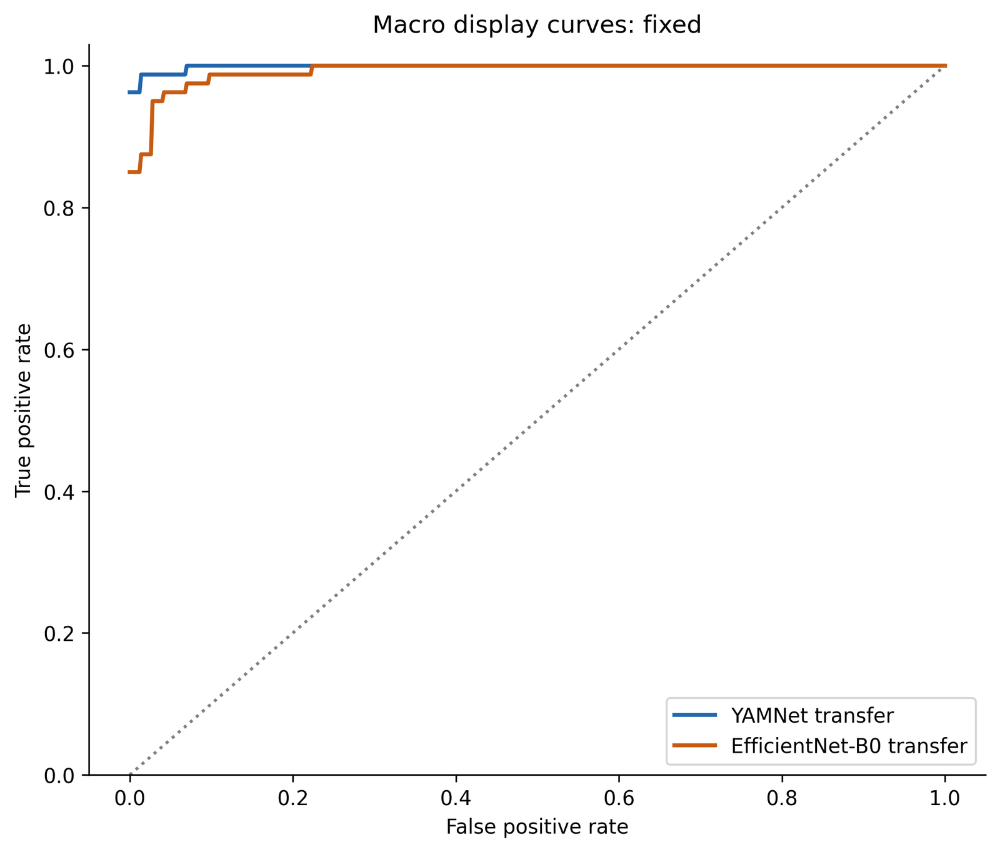

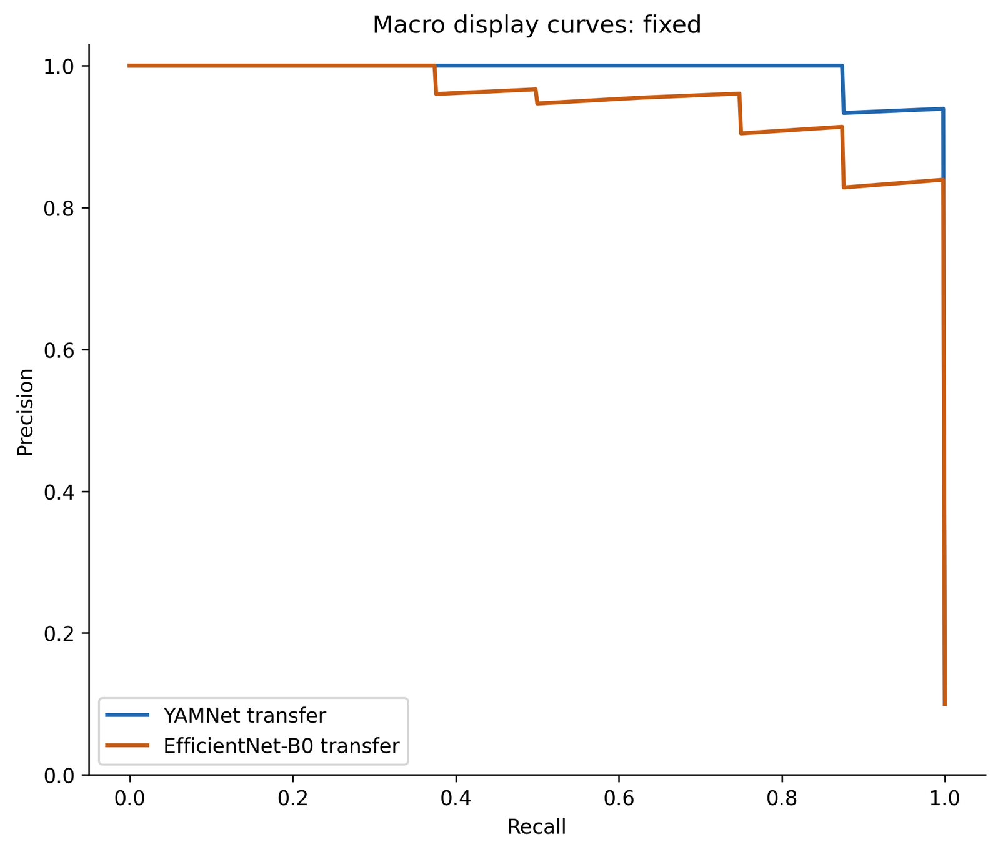

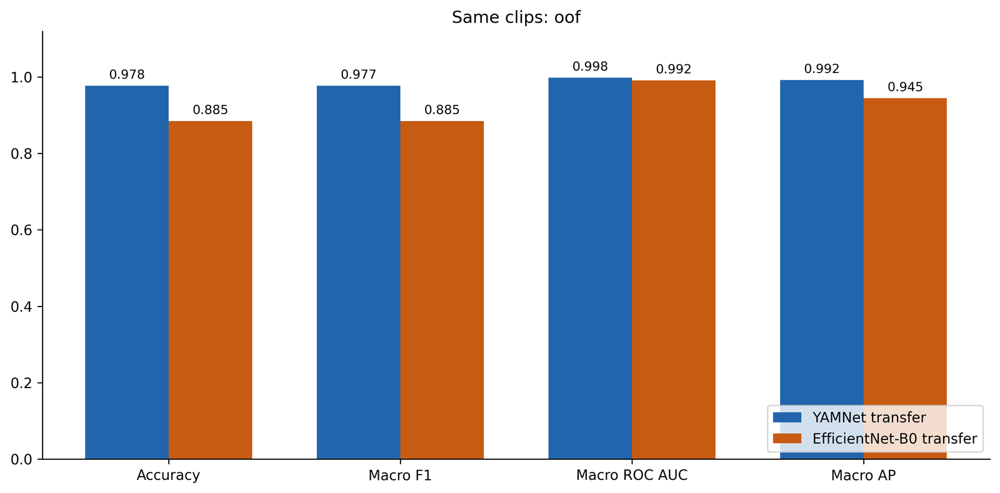

...

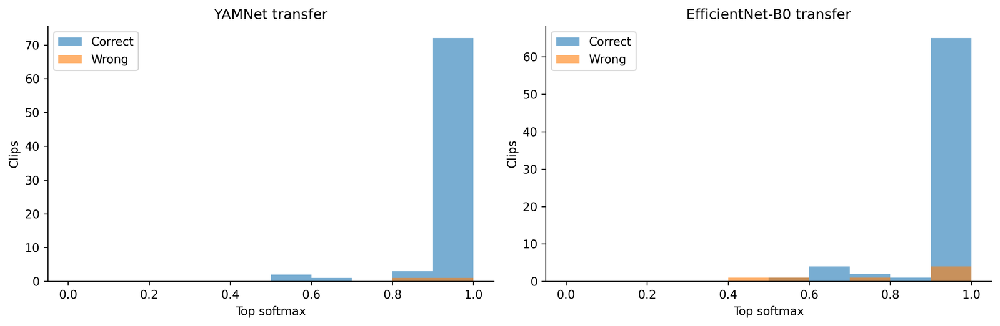

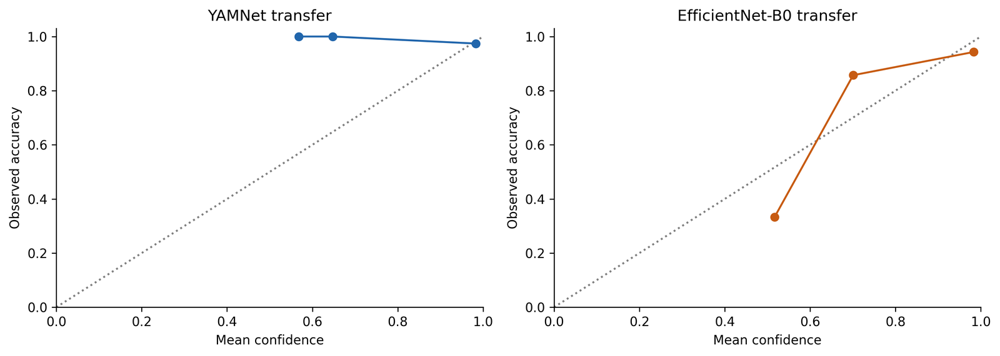

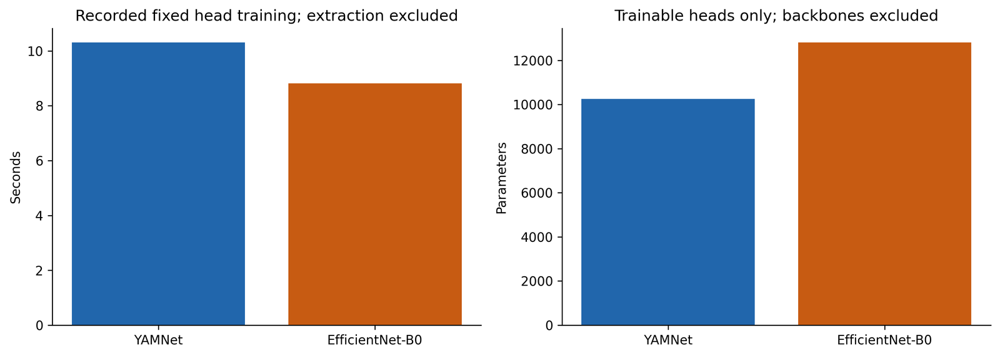

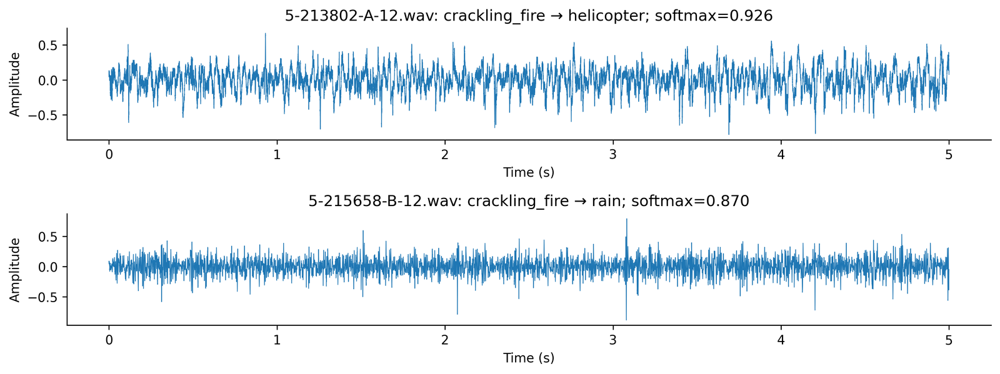

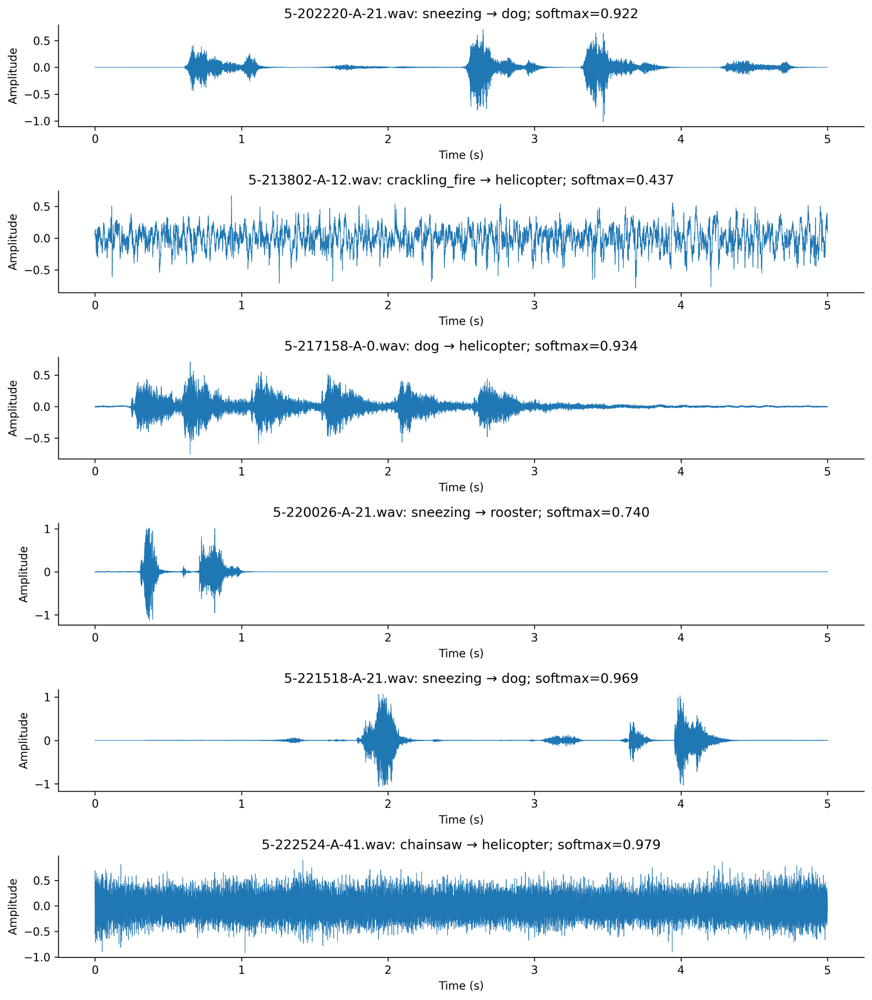

In [14]:
def read_frame(name,run):
    return pd.read_csv(OUT/f'predictions/{name}_{run}.csv').sort_values('filename').reset_index(drop=True)


def comparison_figures(results):
    rows=[]
    for run in ['fixed','oof']:
        for name in NAMES:
            rows.append(dict(model=name,evaluation=run,**{k:results[name][run][k] for k in ['count','correct','accuracy','macro_f1','macro_roc_auc','macro_ap']}))
        keys=['accuracy','macro_f1','macro_roc_auc','macro_ap']; x=np.arange(4)
        fig,ax=plt.subplots(figsize=(10,5))
        for i,name in enumerate(NAMES):
            values=[results[name][run][k] for k in keys]
            bars=ax.bar(x+(i-.5)*.36,values,.36,label=TITLES[name],color=COLORS[name])
            ax.bar_label(bars,fmt='%.3f',fontsize=9,padding=3)
        ax.set(xticks=x,xticklabels=['Accuracy','Macro F1','Macro ROC AUC','Macro AP'],ylim=(0,1.12),title='Same clips: '+run); ax.legend(loc='lower right')
        save(fig,f'comparison_{run}_metrics','Екі модельдің бірдей клиптердегі негізгі метрикалары','comparison')
        fig,ax=plt.subplots(figsize=(12,4)); x=np.arange(10)
        for i,name in enumerate(NAMES):
            ax.bar(x+(i-.5)*.38,[results[name][run]['classification_report'][label]['f1-score'] for label in LABELS],.38,label=TITLES[name],color=COLORS[name])
        ax.set(xticks=x,xticklabels=LABELS,ylim=(0,1.08),ylabel='F1',title=f'Per-class F1: {run}'); plt.setp(ax.get_xticklabels(),rotation=35,ha='right'); ax.legend()
        save(fig,f'comparison_{run}_per_class_f1','Санаттар бойынша F1 салыстыруы','comparison')
        for kind in ['roc','precision_recall']:
            fig,ax=plt.subplots(figsize=(7,6))
            for name in NAMES:
                grid,roc,pr=macro_curves(read_frame(name,run))
                ax.plot(grid,roc if kind=='roc' else pr,lw=2,label=TITLES[name],color=COLORS[name])
            if kind=='roc': ax.plot([0,1],[0,1],':',color='gray')
            ax.set(xlabel='False positive rate' if kind=='roc' else 'Recall',ylabel='True positive rate' if kind=='roc' else 'Precision',
                   title=f'Macro display curves: {run}',ylim=(0,1.03)); ax.legend()
            save(fig,f'comparison_{run}_{kind}','Санаттық қисықтардың көрсетілім үшін интерполяцияланған орташа мәндері','comparison')
    table=pd.DataFrame(rows); table.to_csv(OUT/'tables/model_comparison.csv',index=False); print(table.to_string(index=False))
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    fold_tables={n:pd.read_csv(OUT/f'tables/{n}_fold_scores.csv') for n in NAMES}
    for name in NAMES:
        f=fold_tables[name]
        for ax,key in zip(axes,['accuracy','macro_f1']):
            ax.plot(f.fold,f[key],'o-',label=TITLES[name],color=COLORS[name]); ax.set(xticks=range(1,6),ylim=(0,1.03),xlabel='Test fold',ylabel=key); ax.legend()
    save(fig,'comparison_folds','Бірдей бес сыртқы fold бойынша нәтижелер','comparison')
    fig,ax=plt.subplots(figsize=(8,4)); delta=fold_tables[NAMES[0]].accuracy-fold_tables[NAMES[1]].accuracy
    ax.bar(range(1,6),delta*100,color='#607d8b'); ax.axhline(0,color='black',lw=.7)
    ax.set(xlabel='Test fold',ylabel='YAMNet minus EfficientNet (percentage points)',xticks=range(1,6),title='Paired fold accuracy difference')
    save(fig,'comparison_fold_difference','Accuracy айырмасы пайыздық тармақпен берілген','comparison')
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for name in NAMES:
        h=pd.read_csv(OUT/f'history/{name}_fixed.csv')
        for ax,key in zip(axes,['loss','accuracy']):
            for phase,style in [('train','-'),('validation','--')]:
                ax.plot(h.epoch,h[f'{phase}_{key}'],style,label=TITLES[name]+' '+phase,color=COLORS[name])
            ax.set(xlabel='Epoch',ylabel=key); ax.legend(fontsize=8)
    save(fig,'comparison_fixed_training','Fixed split train және validation динамикасы','comparison')
    left,right=[read_frame(n,'oof') for n in NAMES]
    assert left.filename.tolist()==right.filename.tolist() and np.array_equal(left.true_index,right.true_index)
    a=(left.true_index==left.predicted_index).to_numpy(); b=(right.true_index==right.predicted_index).to_numpy()
    paired=np.array([[(a&b).sum(),(a&~b).sum()],[(~a&b).sum(),(~a&~b).sum()]])
    fig,ax=plt.subplots(figsize=(6,5)); ax.imshow(paired,cmap='Blues')
    for i in range(2):
        for j in range(2): ax.text(j,i,str(paired[i,j]),ha='center',va='center',fontsize=16,color='white' if paired[i,j]>paired.max()/2 else 'black')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Correct','Wrong'],yticklabels=['Correct','Wrong'],xlabel='EfficientNet-B0',ylabel='YAMNet',title='Paired OOF correctness')
    save(fig,'comparison_oof_agreement','Екі модельдің бірдей OOF клиптердегі дұрыс және қате жауаптары','comparison')
    discordant=int(paired[0,1]+paired[1,0]); pvalue=float(binomtest(int(paired[0,1]),discordant,.5).pvalue) if discordant else 1.
    dump(OUT/'metrics/paired_comparison.json',dict(correctness_table=paired.tolist(),mcnemar_exact_two_sided_p=pvalue,
        caveat='Exploratory paired description. OOF heads have overlapping training sets; not an independent external replication.'))
    # Confidence and reliability plots describe the uncalibrated fixed-test scores.
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for name,ax in zip(NAMES,axes):
        f=read_frame(name,'fixed'); correct=f.true_index==f.predicted_index
        for mask,label in [(correct,'Correct'),(~correct,'Wrong')]: ax.hist(f.loc[mask,'confidence'],bins=np.linspace(0,1,11),alpha=.6,label=label)
        ax.set(xlabel='Top softmax',ylabel='Clips',title=TITLES[name]); ax.legend()
    save(fig,'comparison_fixed_confidence','Softmax үлесі қате жауапта да жоғары болуы мүмкін','comparison')
    fig,axes=plt.subplots(1,2,figsize=(11,4)); calibration=[]
    for name,ax in zip(NAMES,axes):
        f=read_frame(name,'fixed'); correct=(f.true_index==f.predicted_index).to_numpy(); conf=f.confidence.to_numpy(); xs=[]; ys=[]
        bins=np.minimum((conf*5).astype(int),4)
        for k in range(5):
            mask=bins==k
            if mask.any():
                xs.append(float(conf[mask].mean())); ys.append(float(correct[mask].mean()))
                calibration.append(dict(model=name,bin=k,count=int(mask.sum()),mean_confidence=xs[-1],accuracy=ys[-1]))
        ax.plot([0,1],[0,1],':',color='gray'); ax.plot(xs,ys,'o-',color=COLORS[name]); ax.set(xlim=(0,1),ylim=(0,1.03),xlabel='Mean confidence',ylabel='Observed accuracy',title=TITLES[name])
    pd.DataFrame(calibration).to_csv(OUT/'tables/reliability_bins.csv',index=False)
    save(fig,'comparison_fixed_reliability','Калибрленбеген score үшін бес interval бойынша сипаттамалық reliability диаграммасы','comparison')
    fig,axes=plt.subplots(1,2,figsize=(11,4)); times=[]; sizes=[]
    for name in NAMES:
        meta=read(OUT/f'history/{name}_fixed.json'); times.append(meta['training_seconds']); sizes.append(meta['head_parameters'])
    short=['YAMNet','EfficientNet-B0']; axes[0].bar(short,times,color=list(COLORS.values())); axes[0].set(ylabel='Seconds',title='Recorded fixed head training; extraction excluded')
    axes[1].bar(short,sizes,color=list(COLORS.values())); axes[1].set(ylabel='Parameters',title='Trainable heads only; backbones excluded')
    save(fig,'comparison_head_resources','Жаңа head параметрлері және сақталған head оқыту уақыты','comparison')
    for name in NAMES:
        frame=read_frame(name,'fixed'); errors=frame[frame.true_index!=frame.predicted_index].head(6)
        fig,axes=plt.subplots(max(1,len(errors)),1,figsize=(11,max(2.7,2.1*len(errors))),squeeze=False)
        if errors.empty:
            axes[0,0].text(.5,.5,'No fixed-test errors in this run',ha='center'); axes[0,0].axis('off')
        for ax,row in zip(axes.flat,errors.itertuples()):
            y=waveform(ASSETS/'audio'/row.filename); ax.plot(np.arange(80000)/16000,y,lw=.5)
            ax.set(title=f'{row.filename}: {row.true_label} → {row.predicted_label}; softmax={row.confidence:.3f}',xlabel='Time (s)',ylabel='Amplitude')
        save(fig,f'{name}_fixed_error_examples','Файл атауы бойынша алғашқы алты test қатесінің нақты waveform мысалдары')
    return table

comparison=comparison_figures(results)


## 11 Нақты аудионы екі оқытылған модельмен болжау

Мысал test fold 5-тен алынады, бірақ ол жаңа бөлек эксперименттік дәлдік бағалауы емес.
Бұл қадам waveform → frozen backbone → train scaler → fixed head жолының кэштен алынған
болжаммен сәйкестігін тексереді. Өз аудиоңызға `predict_audio(Path(...),TF_PYTHON)` шақыруға болады.
Негізгі декодтау SoundFile қолдайтын WAV/FLAC/OGG форматтарына арналған.


In [15]:
def predict_audio(path,yamnet_python=None):
    """Both fixed heads receive features computed from the uploaded waveform."""
    path=Path(path); y=waveform(path)
    worker=ROOT/'yamnet_extract_worker.py'; worker.write_text(TF_EXTRACTOR,encoding='utf-8')
    wave_path=ROOT/'predict_wave.npy'; np.save(wave_path,y[None],allow_pickle=False)
    output=ROOT/'predict_yamnet.npz'; request=ROOT/'predict_request.json'
    dump(request,dict(backbone=str(ASSETS/'backbones/yamnet'),waves=str(wave_path),filenames=[path.name],
                     output=str(output),spectrogram_indices=[0]))
    subprocess.run([str(yamnet_python or sys.executable),str(worker),str(request)],check=True,timeout=300,
                   creationflags=getattr(subprocess,'CREATE_NO_WINDOW',0))
    with np.load(output,allow_pickle=False) as z: yamnet=z['embeddings'][0].copy()
    net=get_efficientnet()
    with torch.inference_mode(): efficient=net(efficientnet_input(mel_for_efficientnet(y))).numpy()[0]
    rows=[]
    for name,value in zip(NAMES,[yamnet,efficient]):
        head,payload=load_head(name)
        x=((value-np.array(payload['mean']))/np.array(payload['std'])).astype('float32')
        with torch.inference_mode(): p=head(torch.from_numpy(x[None])).softmax(1).numpy()[0]
        for rank,index in enumerate(np.argsort(-p),1):
            rows.append(dict(model=TITLES[name],rank=rank,label=LABELS[index],kazakh_label=KAZAKH[index],softmax=float(p[index])))
    result=pd.DataFrame(rows); result.to_csv(OUT/'tables/sample_prediction.csv',index=False)
    wave_path.unlink(missing_ok=True); output.unlink(missing_ok=True)
    print('Audio:',path.name); print(result[result['rank']<=3].to_string(index=False))
    return result


sample=df[df.fold==5].iloc[0]
sample_results=predict_audio(ASSETS/'audio'/sample.filename,TF_PYTHON)
for name in NAMES:
    expected=read_frame(name,'fixed').set_index('filename').loc[sample.filename,[f'prob_{label}' for label in LABELS]].to_numpy(dtype=float)
    actual=sample_results[sample_results.model==TITLES[name]].set_index('label').loc[LABELS,'softmax'].to_numpy()
    np.testing.assert_allclose(actual,expected,rtol=2e-4,atol=2e-5)
print('PASS: live backbone/head predictions match the cached-feature evaluation.')


Audio: 5-151085-A-20.wav
                   model  rank       label   kazakh_label  softmax
         YAMNet transfer     1 crying_baby Сәбидің жылауы 0.999957
         YAMNet transfer     2    sneezing        Түшкіру 0.000019
         YAMNet transfer     3     rooster           Әтеш 0.000012
EfficientNet-B0 transfer     1 crying_baby Сәбидің жылауы 0.999745
EfficientNet-B0 transfer     2         dog     Иттің үруі 0.000156
EfficientNet-B0 transfer     3     rooster           Әтеш 0.000039
PASS: live backbone/head predictions match the cached-feature evaluation.


## 12 Нәтижелердің тұтастығын тексеру және экспорт

10 head үшін train-only scaler, fold бөлінісі, checkpoint label реті және детерминдік eval
тексеріледі. Екі модельге 16-дан негізгі нәтиже графигі бар. Барлығы 58 PNG суреті және
олардың SVG/PDF нұсқалары, CSV/JSON, оқытылған head-тар, нақты history, қысқаша қазақша есеп
және суреттер тізімі `SoundSense_2Models_Results.zip` файлына жиналады.


In [16]:
def audit(df,features,results):
    checks=[]
    for name in NAMES:
        for fold in range(1,6):
            tr,va,te=split_masks(df,fold); model,payload=load_head(name,fold)
            np.testing.assert_allclose(payload['mean'],features[name][tr].mean(0,dtype=np.float64),rtol=1e-12,atol=1e-12)
            np.testing.assert_allclose(payload['std'],np.maximum(features[name][tr].std(0,dtype=np.float64),1e-6),rtol=1e-12,atol=1e-12)
            assert payload['fit_count']==240 and payload['test_fold']==fold and not payload['trained_all_400']
            assert payload['feature_sha256']==sha(ASSETS/f'features/{name}.npz')
            x=np.zeros((2,RECIPES[name]['dimension']),dtype='float32')
            with torch.inference_mode(): first=model(torch.from_numpy(x)); second=model(torch.from_numpy(x))
            torch.testing.assert_close(first,second,rtol=0,atol=0)
            assert first.shape==(2,10) and torch.isfinite(first).all()
            checks.append(dict(model=name,fold=fold,train_only_scaler=True,deterministic_head=True))
        assert results[name]['fixed']['count']==80 and results[name]['oof']['count']==400
        actual=len([f for f in FIGURES if f['name'].startswith(name+'_') and f['kind']=='result' and not f['name'].endswith('_error_examples')])
        assert actual==16,(name,actual)
    assert len(FIGURES)==58,(len(FIGURES),[f['name'] for f in FIGURES])
    assert len(set(f['name'] for f in FIGURES))==len(FIGURES)
    for item in FIGURES:
        image=OUT/item['png']
        with Image.open(image) as im:
            assert min(im.info.get('dpi',(0,0)))>=299
            im.verify()
        item['sha256']=sha(image)
    dump(OUT/'figure_inventory.json',FIGURES)
    dump(OUT/'checks.json',dict(passed=True,original_clips=400,models=NAMES,folds_per_model=5,
        head_checks=checks,figure_count=len(FIGURES),result_plots_per_model=16,
        all_figures_300_dpi=True,backbones_frozen=True,training_seed=42,
        executed_in_colab=bool(os.environ.get('COLAB_RELEASE_TAG')),
        caveat='Checks describe this runtime; consult environment.json for the execution platform.'))
    print('PASS: 400 original clips; 10 heads; train-only scalers; OOF coverage; 58 figures; PNG SVG PDF exports')


def export_report(results):
    lines=['# YAMNet және EfficientNet-B0 салыстыруы','',
      'Екеуі де терең CNN негізіндегі transfer learning моделі. Frozen backbone жаңартылмайды; ESC-10 head оқытылады.',
      'YAMNet: AudioSet → MobileNetV1 → 1024 embedding → mean → train scaler → Dropout 0.2 → Linear 10.',
      'EfficientNet-B0: ImageNet → MBConv/SE → 1280 embedding → train scaler → Dropout 0.2 → Linear 10.',
      'Бірдей 400 ESC-10 клип, seed 42, ресми folds, train 240 / validation 80 / test 80.',
      'Екі model-дің head optimizer рецепттері алдын ала бекітілген; hyperparameter бюджетін теңестіру жүргізілмеген.','',
      '| Модель | Бағалау | Дұрыс | Accuracy | Macro F1 | Macro ROC AUC | Macro AP |',
      '|---|---|---:|---:|---:|---:|---:|']
    for name in NAMES:
        for run in ['fixed','oof']:
            m=results[name][run]
            lines.append(f'| {TITLES[name]} | {run} | {m["correct"]}/{m["count"]} | {m["accuracy"]:.2%} | {m["macro_f1"]:.4f} | {m["macro_roc_auc"]:.4f} | {m["macro_ap"]:.4f} |')
    lines+=['','## Барлық графиктер','']
    for i,item in enumerate(FIGURES,1):
        lines.append(f'{i}. [{item["name"]}]({item["png"]}) — {item["caption"]}.')
    lines+=['','## Әдіснамалық шектеулер','',
      'Бұл жаңа тәуелсіз dataset емес. Fixed fold-5 бұрын белгілі. Екі нұсқа тарихи fixed validation тәжірибелерімен таңдалғандықтан, OOF толық nested architecture selection болып саналмайды.',
      'Бір seed және шағын дерек; fold train жиындары қабаттасады. Fold SD confidence interval емес. AudioSet/ImageNet pretraining пен ESC жазбаларының ықтимал қабаттасуы жеке тексерілмеген.',
      'YAMNet аудиода, EfficientNet суретте алдын ала оқытылған. Бұл pretraining domain және frontend-тері бөлек екі толық жүйенің салыстыруы; айырмашылықты архитектураның таза әсеріне жатқызуға болмайды.',
      'Score calibration оқытылмаған; reliability тек сипаттамалық. Белгісіз санаттар мен multi-label оқиғалар бағаланбаған. Ең үлкен softmax дұрыстыққа кепілдік бермейді.','',
      '## Дереккөздер','',
      '- ESC-10: https://github.com/karolpiczak/ESC-50',
      '- YAMNet: https://www.tensorflow.org/tutorials/audio/transfer_learning_audio',
      '- MobileNet: https://arxiv.org/abs/1704.04861',
      '- EfficientNet: https://arxiv.org/abs/1905.11946',
      '- Torchvision implementation: https://docs.pytorch.org/vision/0.25/models/generated/torchvision.models.efficientnet_b0.html',
      '- Metrics: https://scikit-learn.org/stable/modules/model_evaluation.html']
    (OUT/'report_kk.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
    pd.DataFrame(FIGURES).to_csv(OUT/'tables/all_figures.csv',index=False)
    dump(OUT/'all_metrics.json',results)
    archive=shutil.make_archive(str(ROOT/'SoundSense_2Models_Results'),'zip',OUT)
    print('Ready:',Path(archive).name)
    return Path(archive)

audit(df,features,results)
RESULT_ARCHIVE=export_report(results)


PASS: 400 original clips; 10 heads; train-only scalers; OOF coverage; 58 figures; PNG SVG PDF exports
Ready: SoundSense_2Models_Results.zip


In [17]:
if IN_COLAB and DOWNLOAD_RESULTS:
    from google.colab import files
    files.download(str(RESULT_ARCHIVE))
else:
    print('Download-ready result archive:',RESULT_ARCHIVE.name)


Download-ready result archive: SoundSense_2Models_Results.zip


## Курстық жұмысқа нәтижені дұрыс жазу

Нақты сандарды осы іске қосылудағы `run/tables/model_comparison.csv` кестесінен алыңыз.
Fixed test пен OOF көрсеткіштерін араластырмаңыз. Бес head — бір архитектураның бес fold-тағы
нұсқалары. Backbone frozen, тек жаңа head оқытылғанын көрсетіңіз.

Екі жүйенің pretraining domain-дері мен frontend-тері бөлек. Сондықтан нәтиже айырмасын тек
архитектураның жеке әсері деп түсіндіруге болмайды. Fixed test бұрын белгілі және осы екі
нұсқаның тарихи іріктеуі fixed validation арқылы жүргізілген: бұл толық nested architecture
selection немесе жаңа сыртқы test емес. Бір seed, 400 клип және overlapping train folds бар.
AudioSet/ImageNet пен ESC жазбаларының ықтимал қабаттасуы тексерілмеген. Белгісіз санат пен
multi-label оқиғалар қамтылмайды; Softmax дұрыс жауап ықтималдығына кепілдік бермейді.

Пайдаланылған ресми дереккөздер: [ESC-50/ESC-10](https://github.com/karolpiczak/ESC-50),
[YAMNet](https://www.tensorflow.org/tutorials/audio/transfer_learning_audio),
[MobileNet](https://arxiv.org/abs/1704.04861), [EfficientNet](https://arxiv.org/abs/1905.11946),
[Torchvision](https://docs.pytorch.org/vision/0.25/models/generated/torchvision.models.efficientnet_b0.html),
[scikit-learn metrics](https://scikit-learn.org/stable/modules/model_evaluation.html).
